# Speculative KV Cache Quantization for Agentic Serving: Part 1 experiments

## Where we were: Part 0 (the baseline)

Part 0 built the measuring setup for our project. `src/baseline_experiment.py` loads a plain
HuggingFace model (Llama-3.2-1B-Instruct) with **no KV cache optimisations** and simulates an agent
session:

* each turn, it feeds in one **tool output** from a real agent run (e.g. grep results, test output),
* keeps the KV cache from earlier turns (`past_key_values`), so memory keeps growing,
* lets the model write 64 tokens of its own reply,
* logs the context length, prefill/decode time and GPU memory every turn.

It was run on two real SWE-bench recordings (Django-10554, 126 turns; SymPy-14248, 108 turns), on
ALFWorld (36 games joined into 514 turns) and on synthetic filler text. It showed the problem we
want to solve: **GPU memory grows in a straight line with context, PyTorch reserves far more memory
than the cache needs, and decoding slows down as the context grows.**

## What this notebook does: Part 1

**Experiment 1: a baseline on more, and more realistic, real data**
* Replays **10 full real agent recordings** (the longest one from each of 10 different open-source
  projects, 18k-56k tokens each) through the same plain model. Unlike Part 0, the memory holds the
  **whole real conversation**: the task, the agent's real messages and commands, and the tool outputs.
* Measures the KV cache size **directly from the cache tensors**, as well as GPU memory and speed.
* Re-runs **one** of these recordings with the **exact Part 0 method** (the Part 0 script, unchanged),
  so the two approaches can be compared on the same data.

**Experiment 2: does the core idea of our proposal work?**
* Has the model make N quick "draft guesses" of what comes next, scores every earlier token with our
  consensus formula `S_i = (1/N) Σ_j max_t A^(j)_{t,i}`, keeps the top tokens at full precision and
  either **quantizes** the rest to 2-bit (our approach) or **evicts** it (what H2O/SnapKV/SpecKV do).
* Measures how much that hurts the model's prediction of the agent's **real** next message, and
  compares against looking-back attention (SnapKV-style), a single greedy guess (SpecKV-style),
  random choice, and an oracle that knows the future.

The model is `unsloth/Llama-3.2-1B-Instruct`, a copy of Meta's Llama-3.2-1B-Instruct with identical
weights that doesn't need a Hugging Face login.

## 1. Check the GPU, install libraries, connect Google Drive

In [3]:
!nvidia-smi
!pip install -q -U transformers accelerate matplotlib

from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/kv_cache_experiments'

Wed Oct 28 16:15:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Write the code files

Each cell below writes one script onto the Colab machine. The Part 0 script
`src/baseline_experiment.py` is written as well, **unchanged**, because step 5 runs it.
The last cell in this section points the `results` folder at Google Drive, so every result file
lands in Drive as soon as it's written.

In [4]:
import os
os.makedirs('/content/kv_project/part1', exist_ok=True)
os.makedirs('/content/kv_project/src', exist_ok=True)

In [5]:
%%writefile /content/kv_project/part1/common.py
"""
Helpers I share across all the Part 1 scripts.

- Loading the converted recordings (data/replay/*.json).
- Turning a recording into model-ready text in the Llama-3 chat format.
- A few small tools for working with the HuggingFace KV cache directly
  (measure it, copy it, cut it). I wrote these to work on both
  transformers 4.x and 5.x, because the cache internals changed between them.
"""

import json
import os
from pathlib import Path

import torch

HERE = Path(__file__).resolve().parent

# ---------------------------------------------------------------------------
# Which recordings I use
# ---------------------------------------------------------------------------

# Experiment 1: the longest recording from each of 10 different projects.
EXP1_INSTANCES = [
    "sphinx-doc__sphinx-8548",
    "django__django-11265",
    "sympy__sympy-12419",
    "astropy__astropy-13398",
    "pytest-dev__pytest-5787",
    "pydata__xarray-4687",
    "mwaskom__seaborn-3069",
    "psf__requests-2931",
    "scikit-learn__scikit-learn-11310",
    "pallets__flask-5014",
]

# The recording I also run with the Part 0 method, so the two can be compared.
PART0_METHOD_INSTANCE = "django__django-11265"

# Experiment 2 cuts its contexts out of these 3 recordings.
EXP2_INSTANCES = [
    "django__django-11265",
    "sympy__sympy-12419",
    "sphinx-doc__sphinx-8548",
]

TRAJ_REPO = "john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash"


def load_replay(path):
    """Load one converted recording: {"instance_id", "resolved", "messages": [...]}."""
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def rel(path):
    """Path relative to this folder, for tidier printouts and logs."""
    try:
        return os.path.relpath(path, HERE)
    except ValueError:  # different drive on Windows
        return str(path)


# ---------------------------------------------------------------------------
# Chat formatting
# ---------------------------------------------------------------------------

def _is_llama3(tokenizer):
    return "<|start_header_id|>" in tokenizer.get_vocab()


def format_message(tokenizer, role, content):
    """Render one chat message as text.

    For Llama-3 I use its own header tokens. Tool outputs go under the
    "ipython" role, which is what Llama-3 calls tool results. Any other model
    gets a plain "role: content" layout.
    """
    if _is_llama3(tokenizer):
        role = "ipython" if role == "tool" else role
        return f"<|start_header_id|>{role}<|end_header_id|>\n\n{content}<|eot_id|>"
    return f"{role}: {content}\n\n"


def assistant_header(tokenizer):
    """The bit of text that tells the model 'the assistant speaks now'."""
    if _is_llama3(tokenizer):
        return "<|start_header_id|>assistant<|end_header_id|>\n\n"
    return "assistant: "


def end_of_turn(tokenizer):
    return "<|eot_id|>" if _is_llama3(tokenizer) else "\n\n"


def bos(tokenizer):
    return tokenizer.bos_token or ""


def build_turns(tokenizer, traj):
    """Split a recording into the chunks I feed the model, one per turn.

    turn 0      = system prompt + task description           + assistant header
    turn k >= 1 = real agent message k + real tool output k  + assistant header

    Each chunk ends on the assistant header, which is exactly where the model
    would start writing the agent's next message, so that's where I time the
    decoding. The real agent message then goes at the start of the next turn.
    """
    msgs = traj["messages"]
    head = [m for m in msgs if m["role"] in ("system", "user")]
    rest = [m for m in msgs if m["role"] in ("assistant", "tool")]

    first = bos(tokenizer) + "".join(format_message(tokenizer, m["role"], m["content"]) for m in head)
    turns = [first + assistant_header(tokenizer)]

    pending_agent = None
    for m in rest:
        if m["role"] == "assistant":
            pending_agent = m["content"]
        elif m["role"] == "tool" and pending_agent is not None:
            turns.append(
                pending_agent + end_of_turn(tokenizer)
                + format_message(tokenizer, "tool", m["content"])
                + assistant_header(tokenizer)
            )
            pending_agent = None
    return turns


def build_pieces(tokenizer, traj):
    """Same conversation as build_turns, but as labelled pieces.

    Returns (pieces, cut_after, targets):
      pieces     list of (label, text), label in system/task/agent/tool/header
      cut_after  cut_after[k] is the index of the piece that ends turn k, so
                 "the context up to turn k" is pieces[: cut_after[k] + 1]
      targets    targets[k] is the real agent message that comes after turn k

    Experiment 2 uses the labels to report which part of the conversation
    the important tokens come from.
    """
    msgs = traj["messages"]
    pieces = [("system", bos(tokenizer))]
    for m in msgs:
        if m["role"] in ("system", "user"):
            label = "system" if m["role"] == "system" else "task"
            pieces.append((label, format_message(tokenizer, m["role"], m["content"])))
    pieces.append(("header", assistant_header(tokenizer)))
    cut_after = [len(pieces) - 1]
    targets = []

    pending_agent = None
    for m in msgs:
        if m["role"] == "assistant":
            pending_agent = m["content"]
        elif m["role"] == "tool" and pending_agent is not None:
            targets.append(pending_agent + end_of_turn(tokenizer))
            pieces.append(("agent", pending_agent + end_of_turn(tokenizer)))
            pieces.append(("tool", format_message(tokenizer, "tool", m["content"])))
            pieces.append(("header", assistant_header(tokenizer)))
            cut_after.append(len(pieces) - 1)
            pending_agent = None
    if pending_agent is not None:
        targets.append(pending_agent + end_of_turn(tokenizer))
    return pieces, cut_after, targets


def tokenize_chunk(tokenizer, text, device):
    # add_special_tokens=False because I put <|begin_of_text|> in turn 0 myself
    return tokenizer(text, return_tensors="pt", add_special_tokens=False).input_ids.to(device)


# ---------------------------------------------------------------------------
# Model loading
# ---------------------------------------------------------------------------

def has_native_bf16():
    """True on GPUs with real bf16 hardware (compute capability 8.0+: RTX 30xx+, A100, L4, H100).

    I don't use torch.cuda.is_bf16_supported() here. It also says True on a
    Colab T4, because bf16 can be emulated there, but then PyTorch's
    memory-efficient attention kernel isn't available and long prefills run
    out of memory (this happened to me on a T4).
    """
    return torch.cuda.get_device_capability()[0] >= 8


def pick_dtype(name="auto"):
    """bf16 on GPUs that really support it, fp16 otherwise (e.g. Colab T4). Both are 2 bytes per value."""
    if name != "auto":
        return getattr(torch, name)
    return torch.bfloat16 if has_native_bf16() else torch.float16


def load_model(model_id, dtype, attn_implementation=None):
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(model_id)
    # device_map="cuda" puts the weights straight on the GPU instead of
    # staging them in system RAM first (helps on machines with little RAM)
    kwargs = {"dtype": dtype, "device_map": "cuda"}
    if attn_implementation:
        kwargs["attn_implementation"] = attn_implementation
    try:
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    except TypeError:
        # older transformers versions call it torch_dtype
        kwargs["torch_dtype"] = kwargs.pop("dtype")
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    model.to("cuda").eval()
    return tokenizer, model


# ---------------------------------------------------------------------------
# KV cache tools
# ---------------------------------------------------------------------------

def cache_layers(cache):
    """Return [(keys, values), ...] per layer, for both old and new transformers caches.

    Each tensor has shape (batch, kv_heads, seq_len, head_dim).
    """
    if hasattr(cache, "layers"):  # transformers >= 4.56
        return [(layer.keys, layer.values) for layer in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


def set_cache_layer(cache, idx, keys, values):
    if hasattr(cache, "layers"):
        cache.layers[idx].keys = keys
        cache.layers[idx].values = values
    else:
        cache.key_cache[idx] = keys
        cache.value_cache[idx] = values


def kv_cache_bytes(cache):
    """How many bytes the KV cache needs (all layers, K and V).

    I measure this straight from the cache tensors. torch.cuda.memory_allocated()
    can't tell the cache apart from the model weights and everything else.
    """
    total = 0
    for k, v in cache_layers(cache):
        total += k.numel() * k.element_size() + v.numel() * v.element_size()
    return total


def clone_cache(cache):
    """An independent copy of a DynamicCache, so I can change or extend it freely."""
    from transformers import DynamicCache

    new = DynamicCache()
    for i, (k, v) in enumerate(cache_layers(cache)):
        new.update(k.clone(), v.clone(), i)
    return new


def expand_cache(cache, n):
    """A copy of the cache with the batch repeated n times (one row per draft guess)."""
    from transformers import DynamicCache

    new = DynamicCache()
    for i, (k, v) in enumerate(cache_layers(cache)):
        new.update(k.repeat(n, 1, 1, 1), v.repeat(n, 1, 1, 1), i)
    return new


def crop_cache(cache, length):
    """Throw away everything after the first `length` positions (undoes generated tokens)."""
    current = cache_layers(cache)[0][0].shape[2]
    if current <= length:
        return
    if hasattr(cache, "crop"):
        # crop(-n) means "remove the last n tokens" in both transformers 4.x and 5.x
        cache.crop(-(current - length))
        return
    for i, (k, v) in enumerate(cache_layers(cache)):
        set_cache_layer(cache, i, k[..., :length, :], v[..., :length, :])

Writing /content/kv_project/part1/common.py


In [6]:
%%writefile /content/kv_project/part1/prepare_data.py
"""
Downloads the real agent recordings and converts them into the two formats I need.

Source: real mini-SWE-agent runs on SWE-bench Verified, the same place the
Part 0 data came from:
github.com/john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash

For every recording it writes:
  data/raw/<id>.traj.json         the original recording (cached, so it's only downloaded once)
  data/replay/<id>.json           the full conversation: system, task, agent lines, tool lines
  data/part0_format/<id>.jsonl    tool lines only, one {"tool_output": ...} per line. This is
                                  exactly what src/convert_swe_trajectories.py (Part 0) produces.

For the replay file, an agent line is the agent's sentence plus the shell
command it actually ran (the command is stored in the recording's tool_calls field).

Usage:
    python prepare_data.py                 # every recording both experiments need
    python prepare_data.py --ids django__django-11265
"""

import argparse
import json
import urllib.request
from pathlib import Path

from common import EXP1_INSTANCES, EXP2_INSTANCES, PART0_METHOD_INSTANCE, TRAJ_REPO

RAW_URL = f"https://raw.githubusercontent.com/{TRAJ_REPO}/main"
HERE = Path(__file__).resolve().parent


def download(url, dest):
    if dest.exists():
        return
    dest.parent.mkdir(parents=True, exist_ok=True)
    print(f"  downloading {url}")
    with urllib.request.urlopen(url) as r:
        dest.write_bytes(r.read())


def agent_text(msg):
    """The agent's sentence plus the command(s) it ran, as one block of text."""
    parts = [msg.get("content") or ""]
    for call in msg.get("tool_calls") or []:
        args = call.get("function", {}).get("arguments", "")
        try:
            cmd = json.loads(args).get("command", args)
        except (json.JSONDecodeError, AttributeError):
            cmd = args
        parts.append(f"```bash\n{cmd}\n```")
    return "\n\n".join(p for p in parts if p)


def convert(instance_id, out_dir):
    raw = out_dir / "raw" / f"{instance_id}.traj.json"
    download(f"{RAW_URL}/trajs/{instance_id}.traj.json", raw)

    report = out_dir / "raw" / f"{instance_id}.report.json"
    try:
        download(f"{RAW_URL}/logs/{instance_id}/report.json", report)
        resolved = json.loads(report.read_text(encoding="utf-8"))[instance_id]["resolved"]
    except Exception:
        resolved = None

    traj = json.loads(raw.read_text(encoding="utf-8"))
    messages = []
    for m in traj["messages"]:
        role = m.get("role")
        if role in ("system", "user", "tool") and isinstance(m.get("content"), str):
            messages.append({"role": role, "content": m["content"]})
        elif role == "assistant":
            messages.append({"role": "assistant", "content": agent_text(m)})

    replay = out_dir / "replay" / f"{instance_id}.json"
    replay.parent.mkdir(parents=True, exist_ok=True)
    replay.write_text(json.dumps({"instance_id": instance_id, "resolved": resolved,
                                  "messages": messages}), encoding="utf-8")

    # Part 0 format: same filter and output as src/convert_swe_trajectories.py
    part0 = out_dir / "part0_format" / f"{instance_id}.jsonl"
    part0.parent.mkdir(parents=True, exist_ok=True)
    n_tool = 0
    with open(part0, "w") as f:
        for m in traj.get("messages", []):
            if m.get("role") != "tool":
                continue
            content = m.get("content")
            if not content or not isinstance(content, str):
                continue
            f.write(json.dumps({"tool_output": content}) + "\n")
            n_tool += 1

    n_agent = sum(m["role"] == "assistant" for m in messages)
    print(f"{instance_id}: {n_agent} agent lines, {n_tool} tool lines, resolved={resolved}")


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--ids", nargs="*", default=None)
    parser.add_argument("--out-dir", type=str, default=str(HERE / "data"))
    args = parser.parse_args()

    ids = args.ids or list(dict.fromkeys(EXP1_INSTANCES + EXP2_INSTANCES + [PART0_METHOD_INSTANCE]))
    for instance_id in ids:
        convert(instance_id, Path(args.out_dir))


if __name__ == "__main__":
    main()

Writing /content/kv_project/part1/prepare_data.py


In [7]:
%%writefile /content/kv_project/part1/exp1_baseline_replay.py
"""
Experiment 1: baseline KV cache profiling on full, real agent recordings.

This builds on the Part 0 baseline (src/baseline_experiment.py): a plain
HuggingFace KV cache that is reused across turns, with memory and latency
logged every turn. I changed three things:

1. The context is the WHOLE real conversation: the task, the real agent's
   messages (with the commands it ran) and the real tool outputs, in the
   Llama-3 chat format. Part 0 keeps only the tool outputs and lets the model
   fill the gaps with its own made-up text.
2. Every turn I still let the model write up to --gen-len tokens so I can time
   decoding, but afterwards I crop those tokens back out of the cache. That way
   the cache always holds exactly the real conversation, nothing invented.
3. I also measure the KV cache size directly from the cache tensors
   (kv_cache_gb), not only total GPU memory.

Usage:
    python exp1_baseline_replay.py --replay data/replay/django__django-11265.json \
        --out results/exp1/replay_django__django-11265.csv
"""

import argparse
import csv
import time
from pathlib import Path

import torch

from common import (build_turns, crop_cache, kv_cache_bytes, load_model, load_replay,
                    pick_dtype, rel, tokenize_chunk)

GB = 1024 ** 3


def forward(model, input_ids, cache):
    # logits_to_keep=1 -> only compute logits for the last position. Prefill
    # chunks can be thousands of tokens long, and full logits would add
    # chunk_len x 128k-vocab floats of memory that has nothing to do with the KV cache.
    try:
        return model(input_ids=input_ids, past_key_values=cache, use_cache=True, logits_to_keep=1)
    except TypeError:
        return model(input_ids=input_ids, past_key_values=cache, use_cache=True)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", type=str, default="unsloth/Llama-3.2-1B-Instruct")
    parser.add_argument("--replay", type=str, required=True, help="data/replay/<id>.json")
    parser.add_argument("--gen-len", type=int, default=64)
    parser.add_argument("--max-turns", type=int, default=None)
    parser.add_argument("--dtype", type=str, default="auto",
                        choices=["auto", "float16", "bfloat16", "float32"])
    parser.add_argument("--out", type=str, required=True)
    parser.add_argument("--seed", type=int, default=0)
    parser.add_argument("--mem-fraction", type=float, default=None,
                        help="Cap PyTorch at this fraction of GPU memory. On Windows the driver "
                             "lets CUDA quietly spill into (very slow) system RAM once the GPU is "
                             "full. With a cap, PyTorch frees its unused cached blocks and retries "
                             "instead, which is what it does on Linux/Colab anyway.")
    args = parser.parse_args()

    torch.manual_seed(args.seed)
    if not torch.cuda.is_available():
        raise RuntimeError("This script needs a CUDA GPU.")
    if args.mem_fraction:
        torch.cuda.set_per_process_memory_fraction(args.mem_fraction)

    dtype = pick_dtype(args.dtype)
    print(f"Loading {args.model} ({dtype})...")
    tokenizer, model = load_model(args.model, dtype)

    traj = load_replay(args.replay)
    turns = build_turns(tokenizer, traj)
    if args.max_turns:
        turns = turns[: args.max_turns]
    # Llama-3 Instruct ends a turn with <|eot_id|>, not with eos_token_id, so I stop on either
    stop_ids = {tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<|eot_id|>")}

    out_path = Path(args.out)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fieldnames = [
        "turn", "context_len", "chunk_len", "gen_len",
        "prefill_ms", "decode_ms", "decode_tok_per_s",
        "kv_cache_gb", "mem_allocated_gb", "mem_reserved_gb", "gpu_used_gb",
    ]

    weights_gb = torch.cuda.memory_allocated() / GB
    print(f"Model weights + buffers: {weights_gb:.2f} GB | {len(turns)} turns "
          f"| instance {traj['instance_id']} (resolved={traj.get('resolved')})")

    cache = None
    context_len = 0
    torch.cuda.reset_peak_memory_stats()

    with open(out_path, "w", newline="") as f_out:
        writer = csv.DictWriter(f_out, fieldnames=fieldnames)
        writer.writeheader()

        for turn, chunk_text in enumerate(turns):
            chunk_ids = tokenize_chunk(tokenizer, chunk_text, "cuda")
            chunk_len = chunk_ids.shape[1]

            # --- PREFILL: read the real agent message + tool output ---
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            with torch.no_grad():
                out = forward(model, chunk_ids, cache)
            torch.cuda.synchronize()
            prefill_ms = (time.perf_counter() - t0) * 1000.0

            cache = out.past_key_values
            context_len += chunk_len
            next_token = out.logits[:, -1:, :].argmax(dim=-1)
            del out

            # --- DECODE: time the model writing its next message ---
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            generated = 0
            with torch.no_grad():
                for _ in range(args.gen_len):
                    step = forward(model, next_token, cache)
                    cache = step.past_key_values
                    next_token = step.logits[:, -1:, :].argmax(dim=-1)
                    generated += 1
                    if next_token.item() in stop_ids:
                        break
            torch.cuda.synchronize()
            decode_ms = (time.perf_counter() - t0) * 1000.0

            # memory while the generated tokens are still in the cache (the peak of the turn)
            mem_alloc = torch.cuda.memory_allocated() / GB
            mem_reserved = torch.cuda.memory_reserved() / GB
            free, total = torch.cuda.mem_get_info()

            # --- UNDO: drop the generated tokens; the real agent message comes in next turn ---
            crop_cache(cache, context_len)
            kv_gb = kv_cache_bytes(cache) / GB

            tok_s = generated / (decode_ms / 1000.0) if decode_ms > 0 else 0.0
            writer.writerow({
                "turn": turn,
                "context_len": context_len,
                "chunk_len": chunk_len,
                "gen_len": generated,
                "prefill_ms": round(prefill_ms, 2),
                "decode_ms": round(decode_ms, 2),
                "decode_tok_per_s": round(tok_s, 2),
                "kv_cache_gb": round(kv_gb, 4),
                "mem_allocated_gb": round(mem_alloc, 3),
                "mem_reserved_gb": round(mem_reserved, 3),
                "gpu_used_gb": round((total - free) / GB, 3),
            })
            f_out.flush()
            print(f"turn {turn:3d} | ctx={context_len:6d} | chunk={chunk_len:5d} | "
                  f"prefill={prefill_ms:7.1f}ms | decode={decode_ms:7.1f}ms ({tok_s:5.1f} tok/s) | "
                  f"kv={kv_gb:.3f}GB alloc={mem_alloc:.2f}GB reserved={mem_reserved:.2f}GB")

    peak = torch.cuda.max_memory_allocated() / GB
    print(f"\nDone. Peak allocated: {peak:.2f} GB. Results in {rel(out_path)}")


if __name__ == "__main__":
    main()

Writing /content/kv_project/part1/exp1_baseline_replay.py


In [8]:
%%writefile /content/kv_project/part1/exp1_plot.py
"""
Makes the plots and summary tables for Experiment 1.

Reads results/exp1/replay_<id>.csv (and part0_method_<id>.csv if it exists) and writes:
  exp1_memory.png                  KV cache size vs context (all recordings) + memory breakdown
  exp1_latency.png                 decode speed and prefill cost vs context (all recordings)
  exp1_per_recording.png           small multiples, one panel per recording
  exp1_replay_vs_part0.png         same recording: my full replay vs the Part 0 method
  exp1_summary.csv / .md           one row per recording
"""

import argparse
import csv
from pathlib import Path

import matplotlib.pyplot as plt

import plot_style as ps
from common import PART0_METHOD_INSTANCE, rel

HERE = Path(__file__).resolve().parent
KB_PER_TOKEN_THEORY = 16 * 8 * 64 * 2 * 2 / 1024  # Llama-3.2-1B: layers*kv_heads*head_dim*(K,V)*bytes


def read(path):
    with open(path) as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        for k, v in r.items():
            r[k] = float(v)
    return rows


def col(rows, key):
    return [r[key] for r in rows]


def short(instance_id):
    repo, num = instance_id.split("__")
    return f"{repo.split('-')[0]}-{num.split('-')[-1]}"


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--results", type=str, default=str(HERE / "results" / "exp1"))
    args = parser.parse_args()
    res = Path(args.results)
    ps.apply()

    runs = {p.stem.replace("replay_", ""): read(p) for p in sorted(res.glob("replay_*.csv"))}
    runs = {k: v for k, v in runs.items() if v}
    if not runs:
        raise SystemExit(f"No replay_*.csv files in {res}")
    longest = max(runs, key=lambda k: runs[k][-1]["context_len"])

    # ---------------- summary table ----------------
    summary = []
    for rid, rows in sorted(runs.items(), key=lambda kv: -kv[1][-1]["context_len"]):
        body = rows[1:] if len(rows) > 1 else rows  # turn 0 includes CUDA warm-up
        kv_per_tok = rows[-1]["kv_cache_gb"] * 1024 ** 2 / rows[-1]["context_len"]
        summary.append({
            "recording": rid,
            "turns": len(rows),
            "final_context_tokens": int(rows[-1]["context_len"]),
            "kv_cache_gb": round(rows[-1]["kv_cache_gb"], 3),
            "kv_kb_per_token": round(kv_per_tok, 1),
            "allocated_gb_end": round(rows[-1]["mem_allocated_gb"], 2),
            "reserved_gb_peak": round(max(col(rows, "mem_reserved_gb")), 2),
            "decode_tok_s_start": round(body[0]["decode_tok_per_s"], 1),
            "decode_tok_s_end": round(rows[-1]["decode_tok_per_s"], 1),
            "decode_slowdown_pct": round(100 * (1 - rows[-1]["decode_tok_per_s"] / body[0]["decode_tok_per_s"]), 1),
            "avg_tokens_generated": round(sum(col(rows, "gen_len")) / len(rows), 1),
        })
    with open(res / "exp1_summary.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(summary[0].keys()))
        w.writeheader()
        w.writerows(summary)
    md = ["| " + " | ".join(summary[0].keys()) + " |", "|" + "---|" * len(summary[0])]
    md += ["| " + " | ".join(str(v) for v in s.values()) + " |" for s in summary]
    (res / "exp1_summary.md").write_text("\n".join(md) + "\n", encoding="utf-8")

    # ---------------- memory ----------------
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    for rows in runs.values():
        a1.scatter([r["context_len"] / 1000 for r in rows], col(rows, "kv_cache_gb"),
                   s=6, color=ps.SERIES[0], alpha=0.5, linewidths=0)
    xmax = max(r[-1]["context_len"] for r in runs.values())
    a1.plot([0, xmax / 1000], [0, xmax * KB_PER_TOKEN_THEORY / 1024 ** 2], color=ps.MUTED,
            linestyle="--", linewidth=1)
    ps.direct_label(a1, xmax / 1000 * 0.55, xmax * KB_PER_TOKEN_THEORY / 1024 ** 2 * 0.62,
                    f"theory: {KB_PER_TOKEN_THEORY:.0f} KB/token")
    a1.set_title(f"KV cache size, all {len(runs)} recordings")
    a1.set_xlabel("Context length (thousand tokens)")
    a1.set_ylabel("KV cache (GB), measured from cache tensors")

    rows = runs[longest]
    x = [r["context_len"] / 1000 for r in rows]
    for i, (key, name) in enumerate([("kv_cache_gb", "KV cache"), ("mem_allocated_gb", "Allocated"),
                                     ("mem_reserved_gb", "Reserved by PyTorch")]):
        a2.plot(x, col(rows, key), color=ps.SERIES[i], label=name)
        ps.direct_label(a2, x[-1], rows[-1][key], name)
    a2.set_title(f"Memory breakdown, longest recording ({short(longest)})")
    a2.set_xlabel("Context length (thousand tokens)")
    a2.set_ylabel("GPU memory (GB)")
    a2.legend(loc="upper left", ncol=3)
    a2.set_xlim(right=x[-1] * 1.28)
    a2.set_ylim(0, max(col(rows, "mem_reserved_gb")) * 1.25)  # headroom so the legend clears the data
    fig.tight_layout()
    fig.savefig(res / "exp1_memory.png", dpi=150)
    plt.close(fig)

    # ---------------- latency ----------------
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    for rows in runs.values():
        body = rows[1:]
        a1.scatter([r["context_len"] / 1000 for r in body], col(body, "decode_tok_per_s"),
                   s=6, color=ps.SERIES[0], alpha=0.5, linewidths=0)
        big = [r for r in body if r["chunk_len"] >= 200]
        a2.scatter([r["context_len"] / 1000 for r in big],
                   [r["prefill_ms"] / r["chunk_len"] * 1000 for r in big],
                   s=6, color=ps.SERIES[0], alpha=0.5, linewidths=0)
    a1.set_title("Decode speed")
    a1.set_xlabel("Context length (thousand tokens)")
    a1.set_ylabel("Tokens generated per second")
    a1.set_ylim(bottom=0)
    a2.set_title("Prefill cost per 1,000 new tokens (chunks ≥ 200 tokens)")
    a2.set_xlabel("Context length (thousand tokens)")
    a2.set_ylabel("Prefill ms per 1k new tokens")
    a2.set_ylim(bottom=0)
    fig.tight_layout()
    fig.savefig(res / "exp1_latency.png", dpi=150)
    plt.close(fig)

    # ---------------- small multiples ----------------
    ids = sorted(runs, key=lambda k: -runs[k][-1]["context_len"])
    ncol = 5
    nrow = (len(ids) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.8 * nrow), sharey=True, squeeze=False)
    for ax, rid in zip(axes.flat, ids):
        rows = runs[rid]
        x = [r["context_len"] / 1000 for r in rows]
        ax.plot(x, col(rows, "kv_cache_gb"), color=ps.SERIES[0], label="KV cache")
        ax.plot(x, col(rows, "mem_allocated_gb"), color=ps.SERIES[1], label="Allocated")
        ax.plot(x, col(rows, "mem_reserved_gb"), color=ps.SERIES[2], label="Reserved")
        ax.set_title(short(rid), fontsize=9)
        ax.set_xlabel("Context (k tokens)", fontsize=8)
    for ax in axes.flat[len(ids):]:
        ax.axis("off")
    axes[0][0].set_ylabel("GB")
    axes[0][0].legend(loc="upper left")
    fig.suptitle("GPU memory per recording", x=0.01, ha="left", fontweight="bold", color=ps.TEXT)
    fig.tight_layout()
    fig.savefig(res / "exp1_per_recording.png", dpi=150)
    plt.close(fig)

    # ---------------- full replay vs Part 0 method ----------------
    p0_path = res / f"part0_method_{PART0_METHOD_INSTANCE}.csv"
    if p0_path.exists() and PART0_METHOD_INSTANCE in runs:
        p0, rp = read(p0_path), runs[PART0_METHOD_INSTANCE]
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
        for i, (rows, name) in enumerate([(rp, "Full recording (Exp 1)"), (p0, "Part 0 method")]):
            a1.plot(col(rows, "turn"), [r["context_len"] / 1000 for r in rows], color=ps.SERIES[i], label=name)
            ps.direct_label(a1, rows[-1]["turn"], rows[-1]["context_len"] / 1000, name)
            a2.plot([r["context_len"] / 1000 for r in rows[1:]], col(rows[1:], "decode_tok_per_s"),
                    color=ps.SERIES[i], label=name)
        a1.set_title(f"Context growth, {short(PART0_METHOD_INSTANCE)}")
        a1.set_xlabel("Turn")
        a1.set_ylabel("Context length (thousand tokens)")
        a1.set_xlim(right=max(rp[-1]["turn"], p0[-1]["turn"]) * 1.3)
        a1.legend(loc="upper left")
        a2.set_title("Decode speed")
        a2.set_xlabel("Context length (thousand tokens)")
        a2.set_ylabel("Tokens generated per second")
        a2.set_ylim(bottom=0)
        a2.legend(loc="lower left")
        fig.tight_layout()
        fig.savefig(res / "exp1_replay_vs_part0.png", dpi=150)
        plt.close(fig)

        with open(res / "exp1_replay_vs_part0.md", "w", encoding="utf-8") as f:
            f.write("| Method | Turns | Final context | Avg tokens generated/turn | Decode tok/s (end) |\n|---|---|---|---|---|\n")
            for rows, name in [(rp, "Full recording (Exp 1)"), (p0, "Part 0 method")]:
                f.write(f"| {name} | {len(rows)} | {int(rows[-1]['context_len'])} | "
                        f"{sum(col(rows, 'gen_len')) / len(rows):.1f} | {rows[-1]['decode_tok_per_s']:.1f} |\n")

    print(f"Wrote plots and summary to {rel(res)}")


if __name__ == "__main__":
    main()

Writing /content/kv_project/part1/exp1_plot.py


In [9]:
%%writefile /content/kv_project/part1/exp2_consensus_poc.py
"""
Experiment 2: proof-of-concept for consensus attention scoring.

The question I'm testing: when a draft model makes N quick guesses about what
comes next, do the context tokens those guesses look at actually matter for
what the agent really does next?

For each context (a real conversation cut just before a real agent message):

1. Prefill the context once.
2. Score every context token with several methods:
     consensus_N{1,2,4,8}  our method: N sampled rollouts of L tokens,
                           S_i = mean_j max_t A^(j)_{t,i}   (eq. 1 in our proposal)
     greedy_N1             one greedy rollout (SpecKV-style)
     snapkv                attention from the last 32 context tokens (looks back, not ahead)
     random                random scores (sanity floor)
     oracle                attention from the REAL next agent message. This is an upper
                           bound I can only compute offline, because it knows the future.
   A^(j) is attention averaged over all layers and heads.
3. For each method and keep-fraction k, keep the top-k% scored tokens (plus 4
   attention-sink tokens and the 64 most recent tokens) and either
     quant   fake-quantize every other token's K/V to 2 bits (our approach), or
     evict   mask every other token out completely (H2O/SnapKV/SpecKV-style).
4. Teacher-force the real next agent message on the modified cache and compare
   it with the untouched cache:
     delta_nll   increase in average negative log-likelihood (lower = better)
     top1_agree  fraction of positions where the top-1 prediction didn't change

For now the draft model and the target model are the same model. That's enough
to test the mechanism; a separate small draft model is the next step.

Usage:
    python exp2_consensus_poc.py --out-dir results/exp2
    python exp2_consensus_poc.py --resume      # continue an interrupted run
"""

import argparse
import csv
import json
from pathlib import Path

import torch
import torch.nn.functional as F

from common import (EXP2_INSTANCES, build_pieces, clone_cache, cache_layers, expand_cache,
                    load_model, load_replay, pick_dtype, rel, set_cache_layer)

HERE = Path(__file__).resolve().parent


# ---------------------------------------------------------------------------
# Building contexts
# ---------------------------------------------------------------------------

def make_samples(tokenizer, traj, target_lens, max_target_tokens):
    """Cut the conversation at the first turn boundary past each target length."""
    pieces, cut_after, targets = build_pieces(tokenizer, traj)
    piece_ids = [tokenizer(t, add_special_tokens=False).input_ids for _, t in pieces]

    samples = []
    used = set()
    for want in target_lens:
        total = 0
        for k, end in enumerate(cut_after):
            total = sum(len(ids) for ids in piece_ids[: end + 1])
            if total >= want:
                break
        if k in used or k >= len(targets):
            continue
        used.add(k)
        ids, labels = [], []
        for (label, _), p in zip(pieces[: end + 1], piece_ids[: end + 1]):
            ids += p
            labels += [label] * len(p)
        tgt = tokenizer(targets[k], add_special_tokens=False).input_ids[:max_target_tokens]
        samples.append({"turn": k, "ids": ids, "labels": labels, "target": tgt})
    return samples


# ---------------------------------------------------------------------------
# Attention helpers
# ---------------------------------------------------------------------------

def mean_attention(attentions, ctx_len):
    """Average over layers and heads; keep only attention to context positions.

    attentions: tuple over layers of (batch, heads, q_len, k_len)
    returns: (batch, q_len, ctx_len) float32
    """
    acc = None
    for a in attentions:
        a = a[..., :ctx_len].float().mean(dim=1)
        acc = a if acc is None else acc + a
    return acc / len(attentions)


@torch.no_grad()
def prefill(model, ids, chunk, window):
    """Prefill the context in chunks. The last `window` tokens are run with
    output_attentions=True to get the SnapKV-style score."""
    cache = None
    body, tail = ids[:, :-window], ids[:, -window:]
    for s in range(0, body.shape[1], chunk):
        out = model(input_ids=body[:, s:s + chunk], past_key_values=cache, use_cache=True)
        cache = out.past_key_values
    out = model(input_ids=tail, past_key_values=cache, use_cache=True, output_attentions=True)
    ctx_len = ids.shape[1]
    snap = mean_attention(out.attentions, ctx_len)[0].sum(dim=0)            # (ctx,)
    snap = F.avg_pool1d(snap[None, None], 7, stride=1, padding=3)[0, 0]       # SnapKV pooling
    return out.past_key_values, out.logits[:, -1, :].float(), snap


@torch.no_grad()
def rollouts(model, cache, last_logits, n, horizon, greedy, temperature, top_p, gen):
    """Run n draft rollouts of `horizon` tokens; return per-branch max attention
    over the horizon, shape (n, ctx), plus the generated token ids."""
    ctx_len = cache_layers(cache)[0][0].shape[2]
    c = expand_cache(cache, n)
    logits = last_logits.repeat(n, 1)
    rows, toks = [], []
    for _ in range(horizon):
        if greedy:
            tok = logits.argmax(dim=-1)
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            sorted_p, idx = probs.sort(dim=-1, descending=True)
            cut = sorted_p.cumsum(dim=-1) - sorted_p > top_p
            sorted_p[cut] = 0
            choice = torch.multinomial(sorted_p / sorted_p.sum(-1, keepdim=True), 1, generator=gen)
            tok = idx.gather(-1, choice).squeeze(-1)
        toks.append(tok)
        out = model(input_ids=tok[:, None], past_key_values=c, use_cache=True, output_attentions=True)
        c = out.past_key_values
        rows.append(mean_attention(out.attentions, ctx_len)[:, -1, :])       # (n, ctx)
        logits = out.logits[:, -1, :].float()
    A = torch.stack(rows, dim=1)                                              # (n, L, ctx)
    return A.max(dim=1).values, torch.stack(toks, dim=1)


@torch.no_grad()
def score_target(model, cache, target, attention_mask=None, want_attn=False):
    """Teacher-force the real next message on `cache`. Returns per-position
    log-probs of the true next token, argmax predictions, and optionally the
    attention from target tokens to the context."""
    ctx_len = cache_layers(cache)[0][0].shape[2]
    out = model(input_ids=target, past_key_values=cache, use_cache=True,
                attention_mask=attention_mask, output_attentions=want_attn)
    logits = out.logits[0, :-1].float()                                       # predicts target[1:]
    logp = torch.log_softmax(logits, dim=-1).gather(-1, target[0, 1:, None]).squeeze(-1)
    pred = logits.argmax(dim=-1)
    attn = mean_attention(out.attentions, ctx_len)[0] if want_attn else None
    return logp, pred, attn


# ---------------------------------------------------------------------------
# Compression
# ---------------------------------------------------------------------------

def fake_quant(x, bits, dim):
    """Asymmetric min-max quantize -> dequantize along `dim` (KIVI-style)."""
    xf = x.float()
    mn = xf.amin(dim=dim, keepdim=True)
    mx = xf.amax(dim=dim, keepdim=True)
    levels = 2 ** bits - 1
    scale = (mx - mn).clamp(min=1e-6) / levels
    q = ((xf - mn) / scale).round().clamp(0, levels)
    return (q * scale + mn).to(x.dtype)


def quantize_positions(cache, low_idx, bits, group=32):
    """Fake-quantize the K/V of positions `low_idx` in place.

    Keys: per-channel scales over groups of `group` tokens (keys have outlier
    channels). Values: per-token scales. This is the KIVI recipe and matches
    the proposal's "channel-wise scaling factors".
    """
    if low_idx.numel() == 0:
        return cache
    for i, (k, v) in enumerate(cache_layers(cache)):
        k_low = k[:, :, low_idx, :]
        n = k_low.shape[2]
        full = (n // group) * group
        parts = []
        if full:
            b, h, _, d = k_low.shape
            g = k_low[:, :, :full].reshape(b, h, full // group, group, d)
            parts.append(fake_quant(g, bits, dim=3).reshape(b, h, full, d))
        if n > full:
            parts.append(fake_quant(k_low[:, :, full:], bits, dim=2))
        k = k.clone()
        v = v.clone()
        k[:, :, low_idx, :] = torch.cat(parts, dim=2)
        v[:, :, low_idx, :] = fake_quant(v[:, :, low_idx, :], bits, dim=3)
        set_cache_layer(cache, i, k, v)
    return cache


def keep_mask(scores, ctx_len, frac, sinks, recent):
    """Top-frac of the middle tokens by score, plus sinks and the recent window."""
    keep = torch.zeros(ctx_len, dtype=torch.bool, device=scores.device)
    keep[:sinks] = True
    keep[ctx_len - recent:] = True
    middle = torch.arange(sinks, ctx_len - recent, device=scores.device)
    n_keep = int(round(frac * middle.numel()))
    if n_keep > 0:
        top = scores[middle].topk(n_keep).indices
        keep[middle[top]] = True
    return keep


def topk_set(scores, frac, sinks, recent):
    ctx_len = scores.numel()
    middle = torch.arange(sinks, ctx_len - recent, device=scores.device)
    n = max(1, int(round(frac * middle.numel())))
    return set(middle[scores[middle].topk(n).indices].tolist())


# ---------------------------------------------------------------------------
# Reporting
# ---------------------------------------------------------------------------

def snippet(tokenizer, ids, i, width=8):
    left = tokenizer.decode(ids[max(0, i - width):i])
    tok = tokenizer.decode(ids[i:i + 1])
    right = tokenizer.decode(ids[i + 1:i + 1 + width])
    clean = lambda s: s.replace("\n", "⏎").replace("|", "\\|").replace("`", "'")
    return f"{clean(left)}**[{clean(tok)}]**{clean(right)}"


def write_token_report(path, tokenizer, sample, scores, labels, guesses, real_next, sinks, recent, n_show=15):
    ids = sample["ids"]
    ctx_len = len(ids)
    s = scores["consensus_N4"]
    middle = torch.arange(sinks, ctx_len - recent, device=s.device)
    order = middle[s[middle].argsort(descending=True)].tolist()

    lines = [f"# Consensus scoring: {sample['instance_id']} (cut at turn {sample['turn']}, {ctx_len} tokens)\n",
             "Scores are consensus_N4: attention from 4 sampled 10-token draft guesses, "
             "max over each guess, averaged over the 4. Sinks (first "
             f"{sinks}) and the recent window (last {recent}) are excluded because they are always kept.\n",
             "## What the 4 draft guesses wrote next\n"]
    lines += [f"{j + 1}. `{g.strip()}`" for j, g in enumerate(guesses)]
    lines += ["\n## What the real agent wrote next (first 300 chars)\n",
              "```", real_next[:300], "```\n",
              f"## Top {n_show} tokens (most important)\n",
              "| Rank | Score | Where | Token in context |", "|---|---|---|---|"]
    for r, i in enumerate(order[:n_show]):
        lines.append(f"| {r + 1} | {s[i].item():.4f} | {labels[i]} | {snippet(tokenizer, ids, i)} |")
    lines += [f"\n## Bottom {n_show} tokens (least important)\n",
              "| Rank | Score | Where | Token in context |", "|---|---|---|---|"]
    for r, i in enumerate(order[-n_show:][::-1]):
        lines.append(f"| {r + 1} | {s[i].item():.6f} | {labels[i]} | {snippet(tokenizer, ids, i)} |")

    # where the top-10% lands, by message type, vs. how much of the context each type is
    top10 = set(order[: max(1, len(order) // 10)])
    lines += ["\n## Where the top 10% of tokens come from\n",
              "| Part of conversation | Share of context | Share of top 10% |", "|---|---|---|"]
    for lab in ["system", "task", "agent", "tool", "header"]:
        in_ctx = sum(1 for i in order if labels[i] == lab)
        in_top = sum(1 for i in top10 if labels[i] == lab)
        if in_ctx:
            lines.append(f"| {lab} | {in_ctx / len(order):.0%} | {in_top / len(top10):.0%} |")
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")


# ---------------------------------------------------------------------------
# Main
# ---------------------------------------------------------------------------

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", type=str, default="unsloth/Llama-3.2-1B-Instruct")
    parser.add_argument("--data-dir", type=str, default=str(HERE / "data" / "replay"))
    parser.add_argument("--instances", nargs="*", default=EXP2_INSTANCES)
    parser.add_argument("--context-lens", nargs="*", type=int, default=[2000, 3000, 4000, 5000],
                        help="Cut each conversation at the first turn boundary past these lengths.")
    parser.add_argument("--report-len", type=int, default=4000,
                        help="Which context length gets the human-readable top/bottom token report.")
    parser.add_argument("--max-target-tokens", type=int, default=256)
    parser.add_argument("--horizon", type=int, default=10, help="L in the proposal")
    parser.add_argument("--max-n", type=int, default=8, help="largest N; smaller N use the first branches")
    parser.add_argument("--temperature", type=float, default=1.0)
    parser.add_argument("--top-p", type=float, default=0.95)
    parser.add_argument("--keep-fracs", nargs="*", type=float, default=[0.05, 0.10, 0.20, 0.40])
    parser.add_argument("--sinks", type=int, default=4)
    parser.add_argument("--recent", type=int, default=64)
    parser.add_argument("--snap-window", type=int, default=32)
    parser.add_argument("--bits", type=int, default=2)
    parser.add_argument("--dtype", type=str, default="auto")
    parser.add_argument("--seed", type=int, default=0)
    parser.add_argument("--out-dir", type=str, default=str(HERE / "results" / "exp2"))
    parser.add_argument("--resume", action="store_true",
                        help="Keep results already in --out-dir and skip contexts that are done.")
    args = parser.parse_args()

    torch.manual_seed(args.seed)
    gen = torch.Generator(device="cuda").manual_seed(args.seed)
    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    dtype = pick_dtype(args.dtype)
    print(f"Loading {args.model} ({dtype}, eager attention so I can read the attention weights)...")
    tokenizer, model = load_model(args.model, dtype, attn_implementation="eager")

    rows, agreement, profiles = [], [], []
    if args.resume and (out_dir / "agreement.csv").exists():
        with open(out_dir / "metrics.csv") as f:
            rows = list(csv.DictReader(f))
        with open(out_dir / "agreement.csv") as f:
            agreement = list(csv.DictReader(f))
        profiles = json.loads((out_dir / "score_profiles.json").read_text(encoding="utf-8"))
    done = {(a["instance_id"], int(a["turn"])) for a in agreement}
    if done:
        print(f"Resuming: {len(done)} contexts already done")

    for instance_id in args.instances:
        traj = load_replay(Path(args.data_dir) / f"{instance_id}.json")
        samples = make_samples(tokenizer, traj, args.context_lens, args.max_target_tokens)
        report_turn = min(samples, key=lambda s: abs(len(s["ids"]) - args.report_len))["turn"]

        for sample in samples:
            if (instance_id, sample["turn"]) in done:
                continue
            sample["instance_id"] = instance_id
            ids = torch.tensor([sample["ids"]], device="cuda")
            target = torch.tensor([sample["target"]], device="cuda")
            ctx_len = ids.shape[1]
            print(f"\n{instance_id} | turn {sample['turn']} | context {ctx_len} tokens | "
                  f"target {target.shape[1]} tokens")

            cache, last_logits, snap = prefill(model, ids, 512, args.snap_window)

            # Reference: uncompressed cache. Also gives the oracle score.
            ref_logp, ref_pred, oracle_attn = score_target(model, clone_cache(cache), target, want_attn=True)
            ref_nll = -ref_logp.mean().item()

            branch_max, branch_toks = rollouts(model, cache, last_logits, args.max_n, args.horizon,
                                               greedy=False, temperature=args.temperature,
                                               top_p=args.top_p, gen=gen)
            greedy_max, _ = rollouts(model, cache, last_logits, 1, args.horizon, greedy=True,
                                     temperature=1.0, top_p=1.0, gen=gen)

            scores = {f"consensus_N{n}": branch_max[:n].mean(dim=0)
                      for n in (1, 2, 4, 8) if n <= args.max_n}
            scores["greedy_N1"] = greedy_max[0]
            scores["snapkv"] = snap
            scores["random"] = torch.rand(ctx_len, device="cuda", generator=gen)
            scores["oracle"] = oracle_attn.max(dim=0).values

            # How much do the sampled branches agree with each other? (top-10% sets)
            sets = [topk_set(branch_max[j], 0.10, args.sinks, args.recent) for j in range(args.max_n)]
            pair_j = [len(a & b) / len(a | b) for x, a in enumerate(sets) for b in sets[x + 1:]]
            cons = topk_set(scores["consensus_N4"], 0.10, args.sinks, args.recent)
            grd = topk_set(scores["greedy_N1"], 0.10, args.sinks, args.recent)
            agreement.append({"instance_id": instance_id, "turn": sample["turn"], "context_len": ctx_len,
                              "branch_pairwise_jaccard_top10": sum(pair_j) / len(pair_j),
                              "consensusN4_vs_greedy_jaccard_top10": len(cons & grd) / len(cons | grd)})

            # Compression runs
            uniform = quantize_positions(clone_cache(cache), torch.arange(args.sinks, ctx_len - args.recent,
                                                                          device="cuda"), args.bits)
            u_logp, u_pred, _ = score_target(model, uniform, target)
            base = {"instance_id": instance_id, "turn": sample["turn"], "context_len": ctx_len,
                    "target_len": target.shape[1], "ref_nll": ref_nll}
            rows.append({**base, "method": f"uniform_{args.bits}bit", "keep_frac": 0.0, "policy": "quant",
                         "delta_nll": -u_logp.mean().item() - ref_nll,
                         "top1_agree": (u_pred == ref_pred).float().mean().item(), "recall_vs_oracle": ""})
            del uniform

            for method, sc in scores.items():
                for frac in args.keep_fracs:
                    keep = keep_mask(sc, ctx_len, frac, args.sinks, args.recent)
                    recall = (len(topk_set(sc, frac, args.sinks, args.recent)
                                  & topk_set(scores["oracle"], frac, args.sinks, args.recent))
                              / len(topk_set(scores["oracle"], frac, args.sinks, args.recent)))
                    low_idx = (~keep).nonzero().squeeze(-1)

                    q = quantize_positions(clone_cache(cache), low_idx, args.bits)
                    q_logp, q_pred, _ = score_target(model, q, target)
                    del q

                    mask = torch.ones(1, ctx_len + target.shape[1], dtype=torch.long, device="cuda")
                    mask[0, :ctx_len] = keep.long()
                    e_logp, e_pred, _ = score_target(model, clone_cache(cache), target, attention_mask=mask)

                    for policy, logp, pred in (("quant", q_logp, q_pred), ("evict", e_logp, e_pred)):
                        rows.append({**base, "method": method, "keep_frac": frac, "policy": policy,
                                     "delta_nll": -logp.mean().item() - ref_nll,
                                     "top1_agree": (pred == ref_pred).float().mean().item(),
                                     "recall_vs_oracle": round(recall, 4)})

            # Score profile along the context, for the plot
            labels = sample["labels"]
            profiles.append({"instance_id": instance_id, "turn": sample["turn"], "labels": labels,
                             "consensus_N4": scores["consensus_N4"].tolist(),
                             "oracle": scores["oracle"].tolist()})

            if sample["turn"] == report_turn:
                guesses = [tokenizer.decode(t) for t in branch_toks[:4].tolist()]
                write_token_report(out_dir / f"top_tokens_{instance_id}.md", tokenizer, sample, scores,
                                   labels, guesses, tokenizer.decode(sample["target"]),
                                   args.sinks, args.recent)

            q10 = [r for r in rows[-len(scores) * len(args.keep_fracs) * 2:]
                   if r["keep_frac"] == 0.10 and r["policy"] == "quant"]
            print("  ref NLL {:.3f} | delta NLL @ keep 10%, 2-bit rest: {}".format(
                ref_nll, ", ".join(f"{r['method']}={r['delta_nll']:+.3f}" for r in q10)), flush=True)
            del cache
            torch.cuda.empty_cache()
            # I save after every context so an interrupted run keeps what it already finished
            save(out_dir, rows, agreement, profiles, args)

    print(f"\nWrote {len(rows)} rows to {rel(out_dir / 'metrics.csv')}")


def save(out_dir, rows, agreement, profiles, args):
    with open(out_dir / "metrics.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)
    with open(out_dir / "agreement.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(agreement[0].keys()))
        w.writeheader()
        w.writerows(agreement)
    (out_dir / "score_profiles.json").write_text(json.dumps(profiles), encoding="utf-8")
    config = {**vars(args), "data_dir": rel(args.data_dir), "out_dir": rel(args.out_dir)}
    (out_dir / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")


if __name__ == "__main__":
    main()

Writing /content/kv_project/part1/exp2_consensus_poc.py


In [10]:
%%writefile /content/kv_project/part1/exp2_plot.py
"""
Makes the plots and summary tables for Experiment 2.

Reads results/exp2/metrics.csv, agreement.csv, score_profiles.json and writes:
  exp2_quality_vs_keep.png   quality loss vs keep-fraction, quantize vs evict, per scoring method
  exp2_n_sweep.png           does more draft guesses (N) help?
  exp2_recall.png            how well each method finds the tokens the real next message attends to
  exp2_score_profile.png     where along the context the consensus score is high
  exp2_summary.md            the numbers behind the plots
"""

import argparse
import csv
import json
import statistics
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import plot_style as ps
from common import rel

HERE = Path(__file__).resolve().parent

# Fixed color per method (color follows the method, in every chart).
METHODS = [
    ("consensus_N4", "Consensus, N=4 (ours)"),
    ("greedy_N1", "Single greedy guess (SpecKV-style)"),
    ("snapkv", "Past attention (SnapKV-style)"),
    ("random", "Random"),
    ("oracle", "Oracle (real future)"),
]
COLOR = {m: ps.SERIES[i] for i, (m, _) in enumerate(METHODS)}


def load(res):
    with open(res / "metrics.csv") as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        for k in ("keep_frac", "delta_nll", "top1_agree", "ref_nll"):
            r[k] = float(r[k])
        r["recall_vs_oracle"] = float(r["recall_vs_oracle"]) if r["recall_vs_oracle"] else None
    return rows


def mean_by(rows, keys, value):
    groups = defaultdict(list)
    for r in rows:
        if r[value] is not None:
            groups[tuple(r[k] for k in keys)].append(r[value])
    return {k: (statistics.mean(v), statistics.stdev(v) / len(v) ** 0.5 if len(v) > 1 else 0.0, len(v))
            for k, v in groups.items()}


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--results", type=str, default=str(HERE / "results" / "exp2"))
    args = parser.parse_args()
    res = Path(args.results)
    ps.apply()

    rows = load(res)
    fracs = sorted({r["keep_frac"] for r in rows if r["keep_frac"] > 0})
    dnll = mean_by(rows, ("method", "policy", "keep_frac"), "delta_nll")
    agree = mean_by(rows, ("method", "policy", "keep_frac"), "top1_agree")
    uniform = [r for r in rows if r["method"].startswith("uniform")]
    u_name = uniform[0]["method"] if uniform else "uniform"
    u_mean = statistics.mean(r["delta_nll"] for r in uniform) if uniform else None
    n_samples = len({(r["instance_id"], r["turn"]) for r in rows})

    # ---------------- quality vs keep fraction ----------------
    # separate y-scales: quantize losses are ~10x smaller than evict losses
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, policy, title in [(axes[0], "quant", "Rest quantized to 2-bit (our approach)"),
                              (axes[1], "evict", "Rest evicted (H2O / SnapKV / SpecKV approach)")]:
        for m, name in METHODS:
            ys = [dnll[(m, policy, f)][0] for f in fracs]
            es = [dnll[(m, policy, f)][1] for f in fracs]
            xs = [f * 100 for f in fracs]
            ax.errorbar(xs, ys, yerr=es, color=COLOR[m], label=name, marker="o", markersize=4,
                        capsize=2, linewidth=1.6, linestyle=":" if m == "oracle" else "-")
        if policy == "quant" and u_mean is not None:
            ax.axhline(u_mean, color=ps.MUTED, linestyle="--", linewidth=1)
            ax.annotate(f"everything 2-bit ({u_name})", (fracs[-1] * 100, u_mean), xytext=(0, 4),
                        textcoords="offset points", ha="right", fontsize=8, color=ps.TEXT_2)
        ax.axhline(0, color=ps.TEXT_2, linewidth=0.8)
        ax.set_title(title)
        ax.set_xlabel("% of middle tokens kept at full precision")
    axes[0].set_ylabel("Quality loss: Δ NLL of the real next agent message\n(lower is better, 0 = no loss)")
    axes[1].set_ylabel("Δ NLL (note: different scale)")
    axes[1].legend(loc="upper right")
    fig.suptitle(f"Experiment 2: which tokens to keep? (mean ± s.e. over {n_samples} contexts)",
                 x=0.01, ha="left", fontweight="bold", color=ps.TEXT)
    fig.tight_layout()
    fig.savefig(res / "exp2_quality_vs_keep.png", dpi=150)
    plt.close(fig)

    # ---------------- N sweep ----------------
    ns = sorted(int(m.split("_N")[1]) for m in {r["method"] for r in rows} if m.startswith("consensus_N"))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, policy, title in [(axes[0], "quant", "Rest quantized to 2-bit"), (axes[1], "evict", "Rest evicted")]:
        for f in fracs:
            if f not in (0.05, 0.10, 0.20):
                continue
            ys = [dnll[(f"consensus_N{n}", policy, f)][0] for n in ns]
            ax.plot(ns, ys, marker="o", markersize=4, color=ps.SERIES[[0.05, 0.10, 0.20].index(f)],
                    label=f"keep {f:.0%}")
            ps.direct_label(ax, ns[-1], ys[-1], f"keep {f:.0%}")
        ax.set_xscale("log", base=2)
        ax.set_xticks(ns, [str(n) for n in ns])
        ax.set_xlim(right=ns[-1] * 1.6)
        ax.set_title(title)
        ax.set_xlabel("Number of draft guesses N (sampled)")
    axes[0].set_ylabel("Δ NLL (lower is better)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncol=3)
    fig.suptitle("Do more guesses help?", x=0.01, ha="left", fontweight="bold", color=ps.TEXT)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(res / "exp2_n_sweep.png", dpi=150)
    plt.close(fig)

    # ---------------- recall vs oracle ----------------
    rec = mean_by([r for r in rows if r["policy"] == "quant"], ("method", "keep_frac"), "recall_vs_oracle")
    fig, ax = plt.subplots(figsize=(8, 3.6))
    plotted = [(m, n) for m, n in METHODS if m != "oracle"]
    width = 0.8 / len(plotted)
    for i, (m, name) in enumerate(plotted):
        xs = [j + (i - (len(plotted) - 1) / 2) * width for j in range(len(fracs))]
        ys = [rec[(m, f)][0] * 100 for f in fracs]
        ax.bar(xs, ys, width=width * 0.92, color=COLOR[m], label=name)
    ax.set_xticks(range(len(fracs)), [f"top {f:.0%}" for f in fracs])
    ax.set_ylabel("% of oracle's top tokens found")
    ax.set_ylim(0, 100)
    ax.set_title("How many of the truly-needed tokens does each method find?")
    ax.legend(loc="upper left")
    fig.tight_layout()
    fig.savefig(res / "exp2_recall.png", dpi=150)
    plt.close(fig)

    # ---------------- score profile ----------------
    profiles = json.loads((res / "score_profiles.json").read_text(encoding="utf-8"))
    p = max(profiles, key=lambda q: len(q["labels"]))
    fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
    shade = {"task": ps.SERIES[3], "agent": ps.SERIES[2], "tool": ps.SERIES[4]}
    for ax, key, title in [(axes[0], "consensus_N4", "Consensus score (N=4 draft guesses)"),
                           (axes[1], "oracle", "Oracle score (attention from the real next message)")]:
        labels = p["labels"]
        start = 0
        for i in range(1, len(labels) + 1):
            if i == len(labels) or labels[i] != labels[start]:
                if labels[start] in shade:
                    ax.axvspan(start, i, color=shade[labels[start]], alpha=0.12, linewidth=0)
                start = i
        # skip the 4 attention sinks and the last 64 (recent window): always kept, and they dwarf the rest
        ys = p[key][4:-64]
        ax.plot(range(4, 4 + len(ys)), ys, color=ps.SERIES[0], linewidth=0.8)
        ax.set_title(title, fontsize=10)
        ax.set_ylabel("score")
    axes[1].set_xlabel("Position in context (token)")
    axes[0].legend(handles=[Patch(color=c, alpha=0.3, label=l) for l, c in shade.items()],
                   loc="upper left", ncol=3)
    fig.suptitle(f"Where attention lands: {p['instance_id']}, turn {p['turn']}",
                 x=0.01, ha="left", fontweight="bold", color=ps.TEXT)
    fig.tight_layout()
    fig.savefig(res / "exp2_score_profile.png", dpi=150)
    plt.close(fig)

    # ---------------- summary ----------------
    lines = [f"Contexts evaluated: {n_samples}\n",
             f"Everything-2-bit baseline ({u_name}): Δ NLL = {u_mean:+.3f}\n" if u_mean is not None else "",
             "### Δ NLL (lower is better), mean over contexts\n",
             "| Method | Policy | " + " | ".join(f"keep {f:.0%}" for f in fracs) + " |",
             "|---|---|" + "---|" * len(fracs)]
    all_methods = [m for m, _ in METHODS] + [f"consensus_N{n}" for n in ns if n != 4]
    for policy in ("quant", "evict"):
        for m in all_methods:
            if (m, policy, fracs[0]) in dnll:
                lines.append(f"| {m} | {policy} | " + " | ".join(f"{dnll[(m, policy, f)][0]:+.3f}" for f in fracs) + " |")
    lines += ["\n### Top-1 agreement with the uncompressed model (higher is better)\n",
              "| Method | Policy | " + " | ".join(f"keep {f:.0%}" for f in fracs) + " |",
              "|---|---|" + "---|" * len(fracs)]
    for policy in ("quant", "evict"):
        for m in all_methods:
            if (m, policy, fracs[0]) in agree:
                lines.append(f"| {m} | {policy} | " + " | ".join(f"{agree[(m, policy, f)][0]:.1%}" for f in fracs) + " |")
    lines += ["\n### Recall of the oracle's top tokens\n",
              "| Method | " + " | ".join(f"top {f:.0%}" for f in fracs) + " |", "|---|" + "---|" * len(fracs)]
    for m in all_methods:
        if m != "oracle" and (m, fracs[0]) in rec:
            lines.append(f"| {m} | " + " | ".join(f"{rec[(m, f)][0]:.1%}" for f in fracs) + " |")
    with open(res / "agreement.csv") as f:
        ag = list(csv.DictReader(f))
    bj = statistics.mean(float(a["branch_pairwise_jaccard_top10"]) for a in ag)
    cg = statistics.mean(float(a["consensusN4_vs_greedy_jaccard_top10"]) for a in ag)
    lines += ["\n### Do the guesses agree? (overlap of top-10% token sets, Jaccard)\n",
              f"- Between two different sampled guesses: {bj:.2f}",
              f"- Between consensus N=4 and the single greedy guess: {cg:.2f}"]
    (res / "exp2_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print(f"Wrote plots and summary to {rel(res)}")


if __name__ == "__main__":
    main()

Writing /content/kv_project/part1/exp2_plot.py


In [11]:
%%writefile /content/kv_project/part1/plot_style.py
"""Shared matplotlib style: one validated categorical palette, quiet axes, thin marks."""

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

# Categorical slots in fixed order (validated light-mode palette).
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TEXT = "#0b0b0b"
TEXT_2 = "#52514e"
MUTED = "#8a8984"
GRID = "#e6e5e1"
SURFACE = "#fcfcfb"


def apply():
    plt.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": TEXT_2,
        "axes.titlecolor": TEXT,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": TEXT_2,
        "ytick.color": TEXT_2,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "legend.labelcolor": TEXT_2,
        "lines.linewidth": 1.6,
        "font.size": 9,
    })


def direct_label(ax, x, y, text):
    """Label a line at its end, in text ink (identity is carried by the line itself)."""
    ax.annotate(text, (x, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=TEXT_2)

Writing /content/kv_project/part1/plot_style.py


In [12]:
%%writefile /content/kv_project/part1/run_all.py
"""
Runs everything in order:

  1. prepare_data.py                 download + convert the recordings
  2. exp1_baseline_replay.py x 10    Experiment 1, full-recording replay on each recording
  3. src/baseline_experiment.py      the Part 0 script, unchanged, on one new recording
  4. exp1_plot.py                    Experiment 1 plots + summary
  5. exp2_consensus_poc.py           Experiment 2, consensus scoring proof-of-concept
  6. exp2_plot.py                    Experiment 2 plots + summary

Finished Experiment 1 recordings are skipped and Experiment 2 resumes where it
stopped, so it's safe to stop and start again.

Usage:
    python run_all.py                       # everything
    python run_all.py --steps exp2 exp2_plot
"""

import argparse
import json
import os
import subprocess
import sys
from pathlib import Path

from common import EXP1_INSTANCES, PART0_METHOD_INSTANCE, has_native_bf16, rel

HERE = Path(__file__).resolve().parent
STEPS = ["data", "exp1", "part0", "exp1_plot", "exp2", "exp2_plot"]


def find_part0_script():
    """Find src/baseline_experiment.py in this folder or any folder above it."""
    for folder in [HERE, *HERE.parents]:
        candidate = folder / "src" / "baseline_experiment.py"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("Couldn't find src/baseline_experiment.py (the Part 0 script).")


def run(args):
    args = [rel(a) if isinstance(a, Path) else str(a) for a in args]
    print("\n$ " + " ".join(args), flush=True)
    subprocess.run([sys.executable, *args], cwd=HERE, check=True)


def n_lines(path):
    with open(path) as f:
        return sum(1 for _ in f)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", type=str, default="unsloth/Llama-3.2-1B-Instruct")
    parser.add_argument("--steps", nargs="*", default=STEPS, choices=STEPS)
    parser.add_argument("--gen-len", type=int, default=64)
    args = parser.parse_args()

    res1 = HERE / "results" / "exp1"
    res1.mkdir(parents=True, exist_ok=True)
    # On Windows, stop CUDA from spilling into system RAM (see --mem-fraction in exp1_baseline_replay.py)
    windows = os.name == "nt"

    if "data" in args.steps:
        run(["prepare_data.py"])

    if "exp1" in args.steps:
        for iid in EXP1_INSTANCES:
            out = res1 / f"replay_{iid}.csv"
            traj = json.loads((HERE / "data" / "replay" / f"{iid}.json").read_text(encoding="utf-8"))
            expected = sum(m["role"] == "tool" for m in traj["messages"]) + 1
            if out.exists() and n_lines(out) - 1 >= expected:  # -1 for the CSV header
                print(f"skip {iid} (already done)")
                continue
            cap = ["--mem-fraction", "0.85"] if windows else []
            run(["exp1_baseline_replay.py", "--model", args.model, "--gen-len", args.gen_len,
                 "--replay", HERE / "data" / "replay" / f"{iid}.json", "--out", out, *cap])

    if "part0" in args.steps:
        tool_file = HERE / "data" / "part0_format" / f"{PART0_METHOD_INSTANCE}.jsonl"
        dtype = "bfloat16" if has_native_bf16() else "float16"
        wrapper = ["run_with_mem_cap.py", "0.85"] if windows else []
        run([*wrapper, find_part0_script(), "--model", args.model, "--tool-outputs", tool_file,
             "--num-turns", n_lines(tool_file), "--gen-len", args.gen_len, "--dtype", dtype,
             "--out", res1 / f"part0_method_{PART0_METHOD_INSTANCE}.csv"])

    if "exp1_plot" in args.steps:
        run(["exp1_plot.py"])

    if "exp2" in args.steps:
        run(["exp2_consensus_poc.py", "--model", args.model, "--resume"])

    if "exp2_plot" in args.steps:
        run(["exp2_plot.py"])


if __name__ == "__main__":
    main()

Writing /content/kv_project/part1/run_all.py


In [13]:
%%writefile /content/kv_project/src/baseline_experiment.py
"""
Baseline KV cache profiling under simulated agentic load.

Runs a manual turn loop: each turn appends a "tool output" chunk to a growing
context (reusing the model's KV cache across turns via past_key_values), then
generates the model's next step. Logs per-turn context length, prefill/decode
latency, and GPU memory usage.

Usage:
    python baseline_experiment.py \
        --model meta-llama/Llama-3.2-1B-Instruct \
        --tool-outputs sample_tool_outputs.jsonl \
        --num-turns 50 --gen-len 64 --out results/baseline.csv

If --tool-outputs is omitted, synthetic filler text is used instead. This is
only for smoke-testing that the harness runs end to end — do NOT use
synthetic-text results in the report. Source real trace chunks (e.g. from
SWE-bench / mini-swe-agent / BFCL trajectories) before collecting real numbers.

Optional: pass --mem-cap-gb to stop the loop once allocated memory crosses a
threshold, simulating a memory-constrained serving environment on hardware
where a single session wouldn't otherwise hit real pressure.
"""

import argparse
import csv
import json
import time
from pathlib import Path

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer


def load_tool_outputs(path: str, num_turns: int) -> list[str]:
    """Load tool-output text chunks from a JSONL trace file.

    Expected format: one JSON object per line with a "tool_output" (or
    "text" / "content") field holding the chunk's raw text. Adapt the key
    name here if your trace source uses a different schema.
    """
    chunks = []
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            obj = json.loads(line)
            text = obj.get("tool_output") or obj.get("text") or obj.get("content")
            if text:
                chunks.append(text)
    if len(chunks) < num_turns:
        raise ValueError(
            f"Trace file only has {len(chunks)} chunks but --num-turns={num_turns}. "
            "Provide more trace data or reduce --num-turns."
        )
    return chunks[:num_turns]


def synthetic_tool_outputs(num_turns: int, tokenizer, approx_tokens: int = 300) -> list[str]:
    """Fallback filler text generator for smoke-testing only.

    NOT representative of real agent workloads -- prefer --tool-outputs with
    real trace data for any numbers that go into the report.
    """
    base = (
        "Reading file src/module.py lines 1-120. Found function definitions: "
        "parse_config, load_data, run_pipeline. No syntax errors detected. "
        "Test suite output: 12 passed, 1 failed (test_edge_case). "
    )
    n_repeats = max(1, approx_tokens // max(1, len(tokenizer.encode(base))))
    chunk = base * n_repeats
    return [chunk for _ in range(num_turns)]


def get_mem_stats():
    return {
        "mem_allocated_gb": torch.cuda.memory_allocated() / (1024 ** 3),
        "mem_reserved_gb": torch.cuda.memory_reserved() / (1024 ** 3),
    }


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", type=str, required=True,
                         help="HF model id or local path, e.g. meta-llama/Llama-3.2-1B-Instruct")
    parser.add_argument("--tool-outputs", type=str, default=None,
                         help="Path to a JSONL file of real tool-output chunks. "
                              "If omitted, synthetic filler text is used (smoke-test only).")
    parser.add_argument("--num-turns", type=int, default=50)
    parser.add_argument("--gen-len", type=int, default=64,
                         help="Max number of tokens to generate per turn (the decode step).")
    parser.add_argument("--mem-cap-gb", type=float, default=None,
                         help="If set, stop the loop once memory_allocated exceeds this many GB.")
    parser.add_argument("--dtype", type=str, default="bfloat16",
                         choices=["float16", "bfloat16", "float32"])
    parser.add_argument("--out", type=str, default="results/baseline.csv")
    parser.add_argument("--seed", type=int, default=0)
    args = parser.parse_args()

    torch.manual_seed(args.seed)
    if not torch.cuda.is_available():
        raise RuntimeError("This script expects a CUDA GPU to collect meaningful memory stats.")

    device = "cuda"
    dtype = getattr(torch, args.dtype)

    print(f"Loading model {args.model} ({args.dtype})...")
    tokenizer = AutoTokenizer.from_pretrained(args.model)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = AutoModelForCausalLM.from_pretrained(args.model, torch_dtype=dtype).to(device)
    model.eval()

    if args.tool_outputs:
        tool_outputs = load_tool_outputs(args.tool_outputs, args.num_turns)
    else:
        print("WARNING: no --tool-outputs provided; using synthetic filler text. "
              "Fine for smoke-testing the harness, NOT for results you report.")
        tool_outputs = synthetic_tool_outputs(args.num_turns, tokenizer)

    out_path = Path(args.out)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    fieldnames = [
        "turn", "context_len", "chunk_len", "gen_len",
        "prefill_ms", "decode_ms", "decode_tok_per_s",
        "mem_allocated_gb", "mem_reserved_gb",
    ]

    past_key_values = None
    context_len = 0

    torch.cuda.reset_peak_memory_stats()

    with open(out_path, "w", newline="") as f_out:
        writer = csv.DictWriter(f_out, fieldnames=fieldnames)
        writer.writeheader()

        for turn in range(args.num_turns):
            chunk_text = tool_outputs[turn]
            chunk_ids = tokenizer(chunk_text, return_tensors="pt").input_ids.to(device)
            chunk_len = chunk_ids.shape[1]

            # --- PREFILL: process the new tool-output chunk against the carried-over cache ---
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            with torch.no_grad():
                out = model(
                    input_ids=chunk_ids,
                    past_key_values=past_key_values,
                    use_cache=True,
                )
            torch.cuda.synchronize()
            prefill_ms = (time.perf_counter() - t0) * 1000.0

            past_key_values = out.past_key_values
            context_len += chunk_len
            next_token = out.logits[:, -1:, :].argmax(dim=-1)
            del out

            # --- DECODE: generate the model's next step, one token at a time ---
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            generated_tokens = 0
            with torch.no_grad():
                for _ in range(args.gen_len):
                    step_out = model(
                        input_ids=next_token,
                        past_key_values=past_key_values,
                        use_cache=True,
                    )
                    past_key_values = step_out.past_key_values
                    next_token = step_out.logits[:, -1:, :].argmax(dim=-1)
                    generated_tokens += 1
                    if next_token.item() == tokenizer.eos_token_id:
                        break
            torch.cuda.synchronize()
            decode_ms = (time.perf_counter() - t0) * 1000.0
            context_len += generated_tokens

            decode_tok_per_s = generated_tokens / (decode_ms / 1000.0) if decode_ms > 0 else 0.0
            mem = get_mem_stats()

            row = {
                "turn": turn,
                "context_len": context_len,
                "chunk_len": chunk_len,
                "gen_len": generated_tokens,
                "prefill_ms": round(prefill_ms, 2),
                "decode_ms": round(decode_ms, 2),
                "decode_tok_per_s": round(decode_tok_per_s, 2),
                "mem_allocated_gb": round(mem["mem_allocated_gb"], 3),
                "mem_reserved_gb": round(mem["mem_reserved_gb"], 3),
            }
            writer.writerow(row)
            f_out.flush()
            print(
                f"turn {turn:3d} | ctx={context_len:6d} | "
                f"prefill={prefill_ms:7.1f}ms | decode={decode_ms:7.1f}ms "
                f"({decode_tok_per_s:5.1f} tok/s) | "
                f"mem_alloc={mem['mem_allocated_gb']:.2f}GB mem_reserved={mem['mem_reserved_gb']:.2f}GB"
            )

            if args.mem_cap_gb is not None and mem["mem_allocated_gb"] >= args.mem_cap_gb:
                print(f"Memory cap of {args.mem_cap_gb} GB reached at turn {turn}. Stopping.")
                break

    peak_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
    print(f"\nDone. Peak memory allocated: {peak_gb:.2f} GB. Results written to {out_path}")


if __name__ == "__main__":
    main()

Writing /content/kv_project/src/baseline_experiment.py


In [14]:
# Save results straight into Google Drive: /content/kv_project/part1/results -> Drive
import shutil
drive_results = f'{DRIVE_DIR}/results'
os.makedirs(drive_results, exist_ok=True)
local_results = '/content/kv_project/part1/results'
if os.path.isdir(local_results) and not os.path.islink(local_results):
    shutil.copytree(local_results, drive_results, dirs_exist_ok=True)  # keep anything already produced
    shutil.rmtree(local_results)
if not os.path.islink(local_results):
    os.symlink(drive_results, local_results)
print('Results will be saved to', drive_results)

Results will be saved to /content/drive/MyDrive/kv_cache_experiments/results


## 3. Download and Convert the Real Agent Recordings

In [15]:
%cd /content/kv_project/part1
!python prepare_data.py

/content/kv_project/part1
  downloading https://raw.githubusercontent.com/john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash/main/trajs/sphinx-doc__sphinx-8548.traj.json
  downloading https://raw.githubusercontent.com/john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash/main/logs/sphinx-doc__sphinx-8548/report.json
sphinx-doc__sphinx-8548: 106 agent lines, 105 tool lines, resolved=True
  downloading https://raw.githubusercontent.com/john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash/main/trajs/django__django-11265.traj.json
  downloading https://raw.githubusercontent.com/john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash/main/logs/django__django-11265/report.json
django__django-11265: 95 agent lines, 94 tool lines, resolved=True
  downloading https://raw.githubusercontent.com/john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash/main/trajs/sympy__sympy-12419.traj.json
  downloading https://raw.githubusercontent.com/john-b-yang/20260901_mini-v2.4.2_gemini-3-5-flash/main/logs/sympy__sympy-12419/re

## 4. Experiment 1a: Replay the full recordings

**What's happening here:** We use 10 Scenerios Recording, Each recording is played back to the model turn by turn, exactly as
it happened:

```
turn 0:  system prompt + task (the bug report)
turn 1:  agent's real message + the command it ran  →  the tool's real output
turn 2:  agent's real message + the command it ran  →  the tool's real output
...
```

On every turn the script:
1. **Prefill:** reads the new agent message + tool output, keeping the KV cache from all earlier turns.
2. **Decode:** lets the model write its own next message (up to 64 tokens, stopping at Llama-3's
   real end-of-turn token `<|eot_id|>`) and times it.
3. **Undo:** removes those generated tokens from the cache again, because in the next turn the
   *real* agent message goes in. So the cache always holds exactly the real conversation.
4. **Log:** context length, prefill/decode time, the **KV cache size measured from the cache
   tensors**, allocated/reserved GPU memory.

One CSV per recording goes to `results/exp1/replay_<id>.csv`. Finished recordings are skipped if
you re-run this cell.

In [16]:
!python run_all.py --steps exp1

skip sphinx-doc__sphinx-8548 (already done)
skip django__django-11265 (already done)
skip sympy__sympy-12419 (already done)
skip astropy__astropy-13398 (already done)
skip pytest-dev__pytest-5787 (already done)
skip pydata__xarray-4687 (already done)
skip mwaskom__seaborn-3069 (already done)
skip psf__requests-2931 (already done)
skip scikit-learn__scikit-learn-11310 (already done)
skip pallets__flask-5014 (already done)


## 5. Experiment 1b: Record the output using the same method as Part 0

**What's happening here:** One of the recordings above (`django__django-11265`) is run again,
this time through the **Part 0 script, unchanged** (`src/baseline_experiment.py`), with the input
prepared in exactly the Part 0 format.

How this differs from 1a:

| | 1a: full recording | 1b: Part 0 method |
|---|---|---|
| What goes into memory | task + real agent messages + real tool outputs | **only the tool outputs** |
| Between tool outputs | the agent's real message | the model's **own 64 made-up tokens** |
| Model's own writing | timed, then removed from memory | **stays in memory** and builds up |
| Stops writing at | Llama-3's end-of-turn token | never stops early (always 64 tokens) |
| Text format | Llama-3 chat format | raw text joined together |
| KV cache size | measured directly | only total GPU memory |

Running both on the same recording shows how much these choices change the context length,
memory and speed we measure.

In [17]:
!python run_all.py --steps part0


$ ../src/baseline_experiment.py --model unsloth/Llama-3.2-1B-Instruct --tool-outputs data/part0_format/django__django-11265.jsonl --num-turns 94 --gen-len 64 --dtype float16 --out results/exp1/part0_method_django__django-11265.csv
Loading model unsloth/Llama-3.2-1B-Instruct (float16)...
config.json: 100% 894/894 [00:00<00:00, 748kB/s]
tokenizer_config.json: 100% 54.7k/54.7k [00:00<00:00, 93.1MB/s]

tokenizer.json: downloading bytes:   8% 1.44M/17.2M [00:00<00:07, 2.05MB/s]
tokenizer.json: downloading bytes: 100% 4.24M/4.24M [00:00<00:00, 4.81MB/s,  415kB/s  ]
tokenizer.json: reconstructing file: 100% 17.2M/17.2M [00:00<00:00, 19.5MB/s, 1.69MB/s  ]
special_tokens_map.json: 100% 454/454 [00:00<00:00, 1.63MB/s]
chat_template.jinja: 100% 3.83k/3.83k [00:00<00:00, 10.1MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

model.safetensors: downloading bytes:   0% 0.00/2.47G [00:00<?, ?B/s]
model.safetensors: downloading bytes:  10% 251M/2.47G [00:01<00:08, 256MB/s, 22.4MB

## 6. Experiment 1: Plots and Summary

### What the Experiment 1 plots show

**Summary tables.** Across the 10 recordings the context grew to 18k–56k tokens over 41–106 turns. The KV cache cost
exactly **32 KB per token** in every recording: 16 layers × 8 KV heads × 64 dims × (K + V) × 2 bytes. Decode speed
fell **79–92%** from start to end, and the longest recording dropped the most (sphinx-8548: 41.5 → 3.3 tok/s).

**`exp1_memory.png`: KV cache size and memory breakdown**
- *Left:* all 10 recordings fall on one straight line, right on the theoretical 32 KB/token line. The KV cache grows
  linearly with context and depends only on token count, not on what the tokens are. At 56k tokens it is 1.71 GB.
- *Right (sphinx-8548):* allocated memory is the model weights (~2.3 GB) plus the KV cache, and grows smoothly to
  ~4 GB. Memory **reserved** by PyTorch behaves very differently. It climbs in a saw-tooth to ~14 GB, collapses to
  ~5 GB, and climbs again, four times. Peak reserved memory is about **3.5× the memory actually in use**. The
  temporary buffers for attention over a long context, plus allocator caching and fragmentation, cost far more GPU
  memory than the cache itself.

**`exp1_latency.png`: decode speed and prefill cost**
- *Decode speed:* this curve gives the clearest result. Speed falls steeply from ~42 tok/s at 2k tokens to ~15 tok/s
  at 10k, ~8 tok/s at 20k, and ~3.5 tok/s at 50k+, roughly inversely with context length. Every new token has to
  read the whole KV cache, so decoding is memory-bandwidth bound and gets slower as the cache grows.
- *Prefill cost per 1k new tokens:* this rises roughly linearly, from ~200 ms at 2k context to ~1,400 ms (up to
  ~2,100 ms) at 50k, about **7× more expensive**. New tokens must attend to the whole history. The scatter widens at
  long contexts.

**`exp1_per_recording.png`: GPU memory per recording**
- The blue (KV cache) and orange (allocated) lines have the same slope in every panel. Recordings differ only in
  how far they extend.
- The green (reserved) line is where they differ. Short recordings (pytest, astropy, pallets, scikit-learn) stay
  around 3–6 GB. Long recordings (sphinx, sympy, django) reach 13–14 GB, the ceiling of the GPU, and sphinx and sympy
  show the saw-tooth pattern where PyTorch frees its cache and starts again.
- Peak reserved memory does not depend on context length alone. psf-2931 reaches ~10 GB at only 22k tokens, while
  astropy stays under 5 GB at 31k. The **size of individual tool outputs** (large prefill chunks) also drives the
  peak.

**`exp1_replay_vs_part0.png`: full recording vs the Part 0 method (django-11265)**
- *Context growth:* the full recording starts at ~2k tokens (system prompt + bug report) and ends at 46.8k. The
  Part 0 method starts near 0 and ends at 41.9k after 94 turns. Both follow the same staircase shape, because the
  big jumps (turns ~57 and ~68) come from the same large tool outputs.
- *Decode speed:* the two curves **lie on top of each other**. Decode speed depends only on context length, not on
  whether the context is real agent text or the model's own filler. The Part 0 curve's brief dip (~18 tok/s near
  1.5k tokens) is a warm-up artefact at the very start.
- The Part 0 method always writes the full 64 tokens (it has no end-of-turn stop), while the real replay averages
  44.5 tokens per turn. Part 0 therefore slightly overstates decode work per turn, but its speed-vs-context results
  are still valid.

**Takeaway for the project:** the KV cache grows linearly and predictably, and long agent sessions become decode-bound.
At 50k tokens, generation is >90% slower than at the start. Shrinking the KV cache (fewer bytes per token) targets
exactly the cost that dominates long agentic sessions.

Wrote plots and summary to results/exp1


| recording | turns | final_context_tokens | kv_cache_gb | kv_kb_per_token | allocated_gb_end | reserved_gb_peak | decode_tok_s_start | decode_tok_s_end | decode_slowdown_pct | avg_tokens_generated |
|---|---|---|---|---|---|---|---|---|---|---|
| sphinx-doc__sphinx-8548 | 106 | 56036 | 1.71 | 32.0 | 4.02 | 14.1 | 41.5 | 3.3 | 92.0 | 45.5 |
| sympy__sympy-12419 | 97 | 50076 | 1.528 | 32.0 | 3.84 | 14.28 | 42.9 | 3.7 | 91.4 | 56.3 |
| django__django-11265 | 95 | 46804 | 1.428 | 32.0 | 3.74 | 14.07 | 41.1 | 3.9 | 90.4 | 44.5 |
| pydata__xarray-4687 | 88 | 33904 | 1.035 | 32.0 | 3.35 | 8.2 | 39.6 | 5.3 | 86.6 | 45.9 |
| astropy__astropy-13398 | 59 | 31381 | 0.958 | 32.0 | 3.27 | 4.8 | 40.6 | 5.7 | 85.9 | 51.4 |
| pytest-dev__pytest-5787 | 41 | 28591 | 0.873 | 32.0 | 3.18 | 5.3 | 33.7 | 6.2 | 81.5 | 41.9 |
| mwaskom__seaborn-3069 | 72 | 27640 | 0.844 | 32.0 | 3.16 | 10.31 | 40.4 | 6.4 | 84.1 | 44.4 |
| psf__requests-2931 | 62 | 22176 | 0.677 | 32.0 | 2.99 | 10.1 | 42.5 | 7.8 | 81.6 | 45.0 |
| scikit-learn__scikit-learn-11310 | 66 | 21598 | 0.659 | 32.0 | 2.97 | 6.23 | 41.9 | 8.0 | 80.9 | 26.1 |
| pallets__flask-5014 | 43 | 18464 | 0.564 | 32.0 | 2.88 | 5.78 | 42.6 | 9.1 | 78.6 | 43.4 |


| Method | Turns | Final context | Avg tokens generated/turn | Decode tok/s (end) |
|---|---|---|---|---|
| Full recording (Exp 1) | 95 | 46804 | 44.5 | 3.9 |
| Part 0 method | 94 | 41923 | 64.0 | 4.4 |


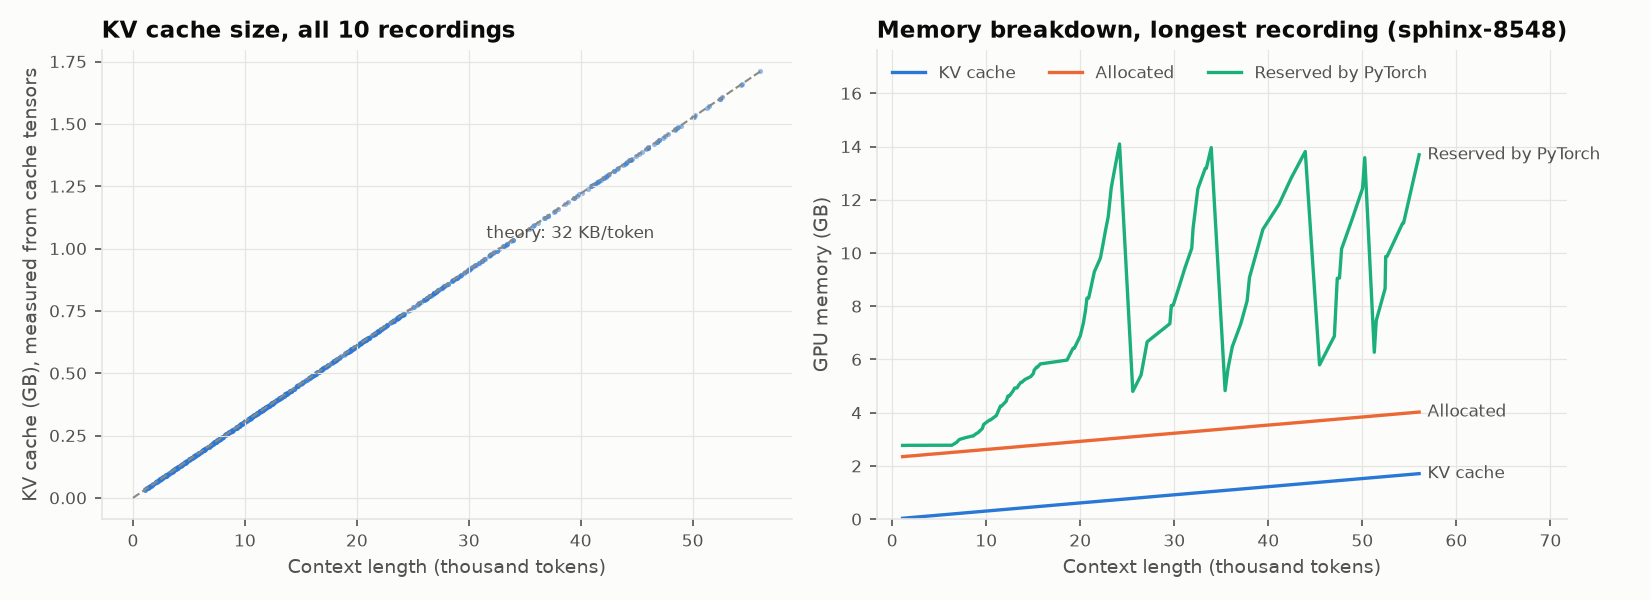

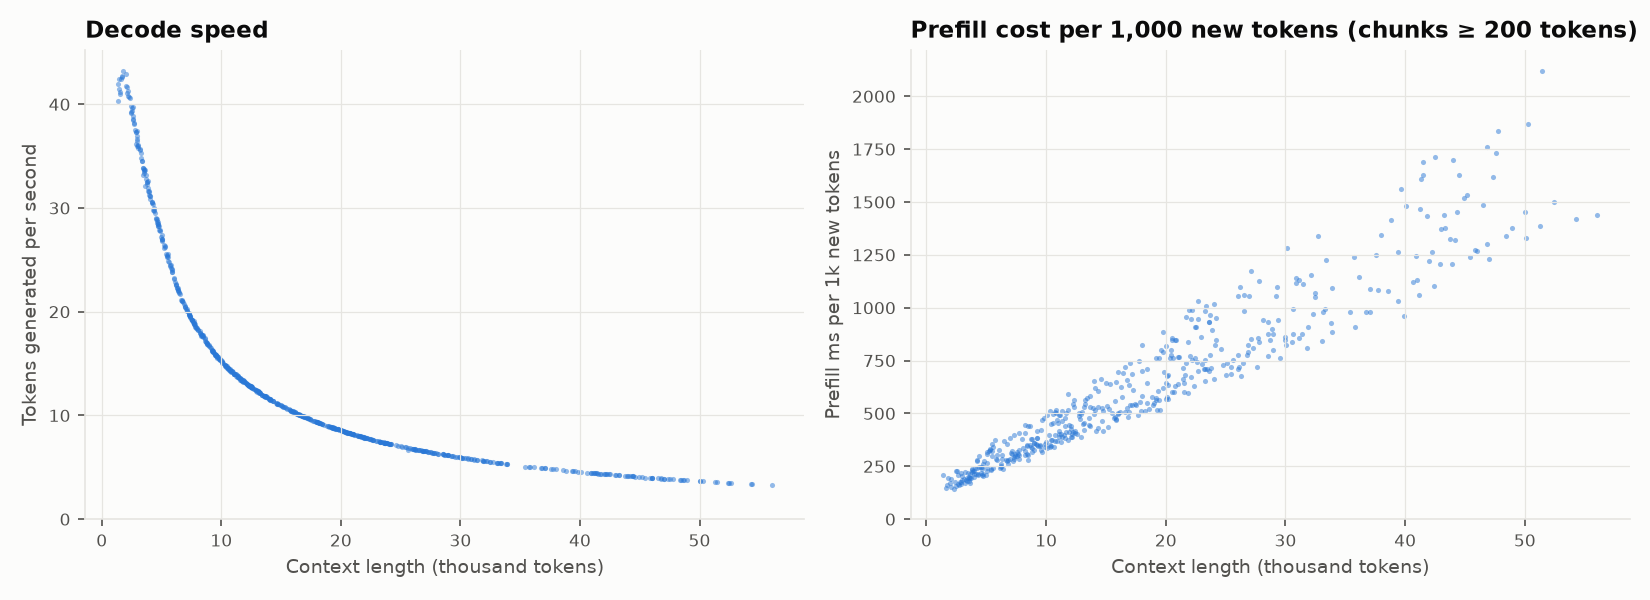

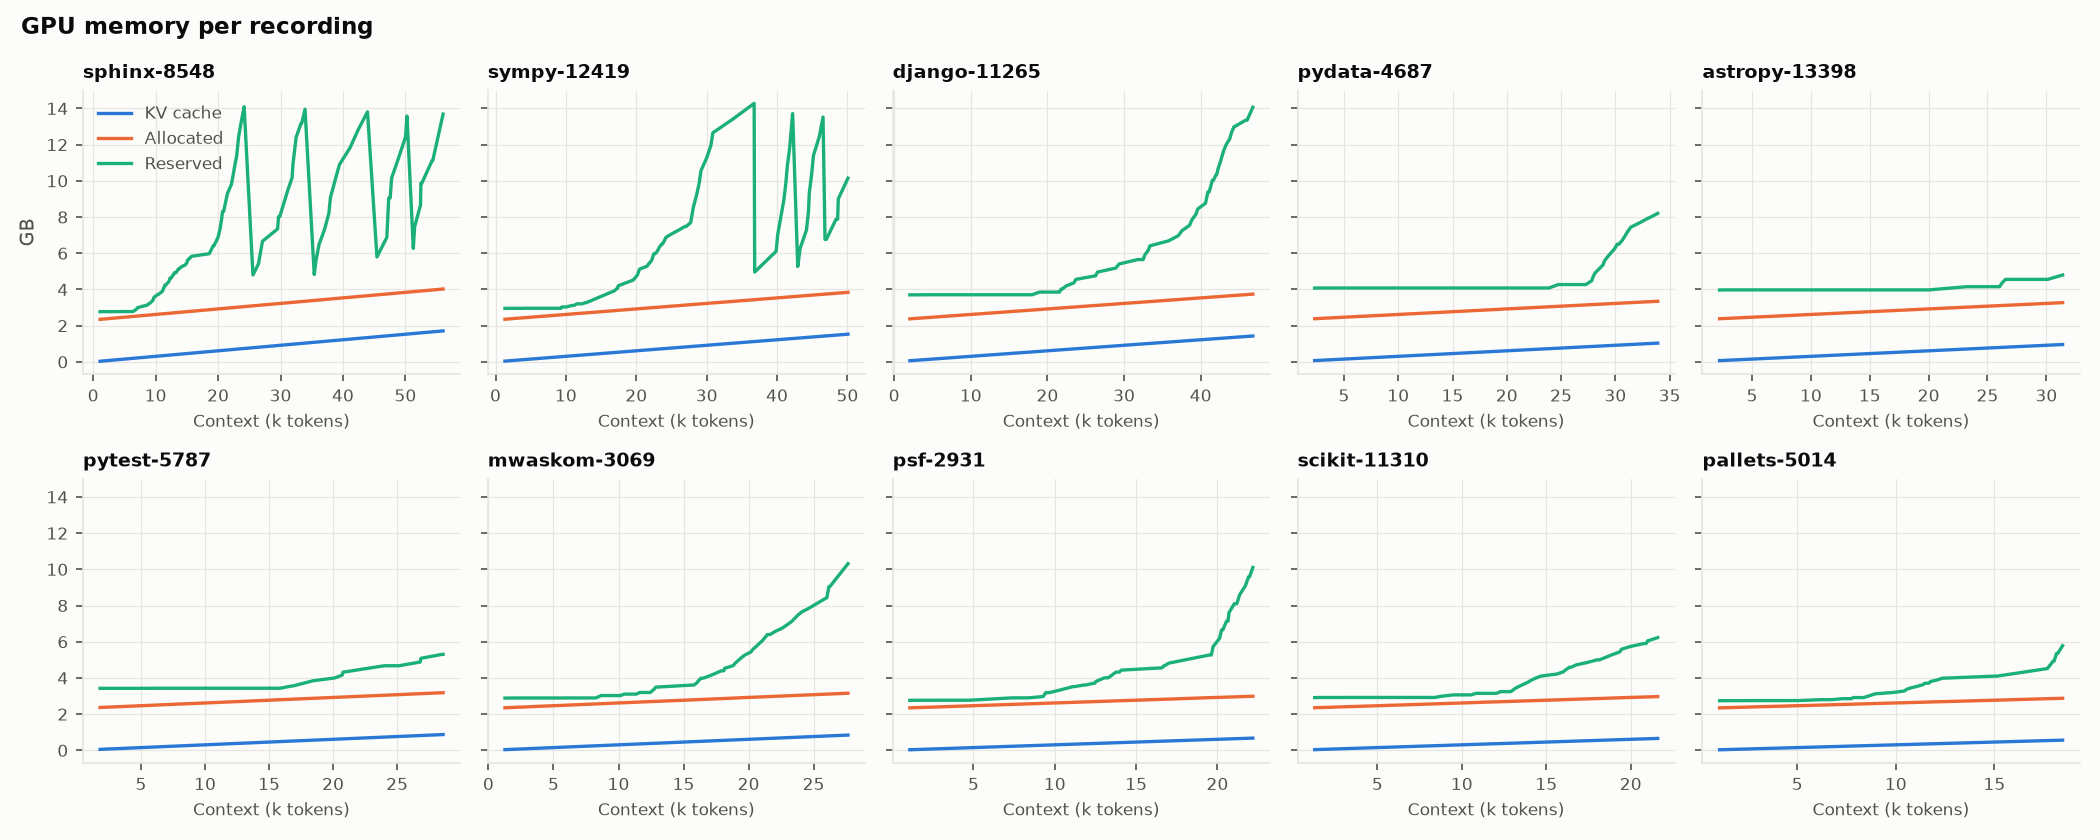

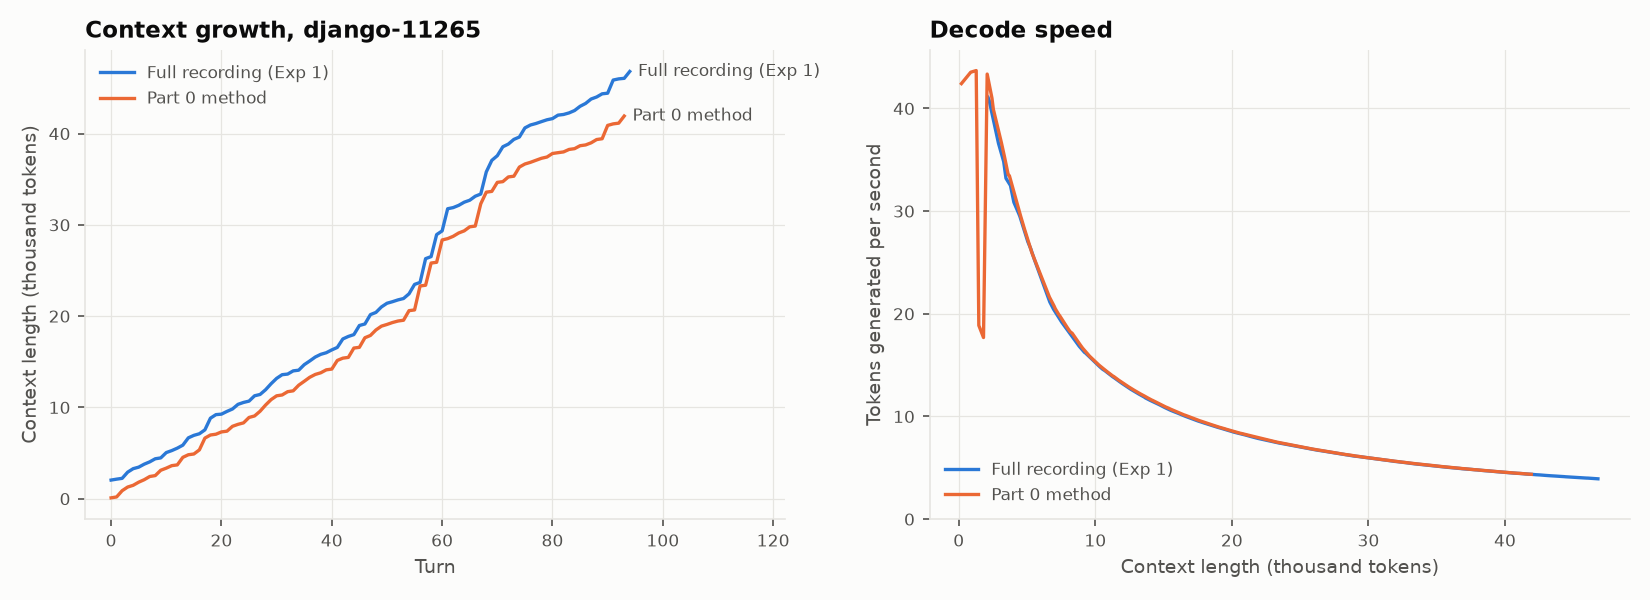

In [18]:
!python exp1_plot.py
from IPython.display import Image, Markdown, display
def show(path):
    # skip anything whose step didn't run
    if not os.path.exists(path):
        print(f'(missing: {path})')
    elif path.endswith('.md'):
        display(Markdown(open(path).read()))
    else:
        display(Image(path))
for name in ['exp1_summary.md', 'exp1_replay_vs_part0.md', 'exp1_memory.png', 'exp1_latency.png',
             'exp1_per_recording.png', 'exp1_replay_vs_part0.png']:
    show(f'results/exp1/{name}')

## 7. Experiment 2: Consensus Scoring Proof-of-Concept

**What's happening here:** 3 of the recordings are cut at about 2k, 3k, 4k and 5k tokens (12 contexts),
each time just **before a real agent message**. For each context:

1. The model makes **8 random draft guesses** of 10 tokens each, plus one greedy guess, and I record
   which earlier tokens each guess pays attention to.
2. Every earlier token gets a score: with our consensus formula (using the first 1, 2, 4 or 8
   guesses), the single greedy guess, looking-back attention (SnapKV-style), random scores, and an
   oracle (attention from the real next message, which knows the future).
3. For each scoring method, the top 5/10/20/40% of tokens stay at full precision (plus the first 4
   and the last 64 tokens). The rest is either **quantized to 2-bit** or **evicted**.
4. The agent's **real** next message is fed in, and I measure how much worse the model predicts it
   than with the untouched memory (Δ NLL: 0 = no damage, lower is better).

Results are saved after every context, so if this stops it continues where it left off.

In [19]:
!python exp2_consensus_poc.py --resume

Loading unsloth/Llama-3.2-1B-Instruct (torch.float16, eager attention so I can read the attention weights)...
Loading weights: 100% 146/146 [00:02<00:00, 63.56it/s]
Resuming: 8 contexts already done

sphinx-doc__sphinx-8548 | turn 4 | context 2286 tokens | target 59 tokens
  ref NLL 1.615 | delta NLL @ keep 10%, 2-bit rest: consensus_N1=-0.010, consensus_N2=-0.020, consensus_N4=-0.030, consensus_N8=+0.012, greedy_N1=+0.028, snapkv=-0.082, random=-0.040, oracle=+0.068

sphinx-doc__sphinx-8548 | turn 7 | context 3605 tokens | target 49 tokens
  ref NLL 0.235 | delta NLL @ keep 10%, 2-bit rest: consensus_N1=+0.075, consensus_N2=+0.075, consensus_N4=+0.014, consensus_N8=+0.029, greedy_N1=+0.023, snapkv=+0.008, random=+0.028, oracle=+0.045

sphinx-doc__sphinx-8548 | turn 9 | context 4180 tokens | target 47 tokens
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers a

## 8. Experiment 2: Plots, Summary and the top/bottom-token Reports

### What the Experiment 2 plots show

**Summary table.** We evaluated 12 contexts (3 recordings × cuts at ~2k–5k tokens). Quantizing *everything* to
2-bit (uniform_2bit) costs Δ NLL = +0.054 on the real next agent message. This is the bar a "keep some tokens at
full precision" method has to beat.

**`exp2_quality_vs_keep.png`: which tokens to keep?**
- *Left: rest quantized to 2-bit (our approach).* All losses are small (−0.01 to +0.08 NLL). At keep 5–10%, the
  methods are within each other's error bars and none clearly beats uniform 2-bit. At keep **20–40%**, consensus
  N=4 drops to **+0.007 and −0.008**, matching the oracle (+0.002, +0.006). The single greedy guess (+0.026, +0.010)
  is worse, and SnapKV stays flat at ~+0.03. Random keeping is noisy and no better than uniform 2-bit. The error
  bars are wide because there are only 12 contexts.
- *Right: rest evicted (H2O / SnapKV / SpecKV approach).* Losses are **10–50× larger** (up to +1.1 NLL), and the
  ranking is clear and consistent at every keep level: **consensus < greedy < SnapKV < random**. At keep 5%,
  consensus loses +0.50 vs +0.61 (greedy), +0.93 (SnapKV), +1.11 (random). The oracle stays at ~0, so the right
  tokens exist; the methods differ in how well they find them.
- *Top-1 agreement (table):* with quantization, every method keeps 92–98% agreement with the uncompressed model.
  With eviction at keep 5%, agreement falls to 80.7% (consensus), 78.9% (greedy), 72.6% (SnapKV) and 65.5% (random).
- **Main point:** keeping the unselected tokens at 2-bit instead of throwing them away makes the system far more
  forgiving of imperfect scoring. A bad choice of tokens costs little under quantization but a lot under eviction.

**`exp2_n_sweep.png`: do more draft guesses (N) help?**
- *Rest evicted:* yes, slightly and fairly steadily. From N=1 to N=8, loss drops 0.519 → 0.475 (keep 5%),
  0.323 → 0.292 (keep 10%), and 0.142 → 0.100 (keep 20%). N=2 is a small bump.
- *Rest quantized:* no clear trend. N=1 is best at keep 5% and 10%, N=4 at keep 20%, and the differences
  (0.01–0.03 NLL) are within the noise seen in the previous plot.
- So more guesses help when a mistake is costly (eviction). With quantization the loss is already near the floor,
  so N barely matters. N=4 is a reasonable middle ground.

**`exp2_recall.png`: how many of the truly needed tokens does each method find?**
- Consensus N=4 finds **43 / 52 / 64 / 75%** of the oracle's top 5 / 10 / 20 / 40% tokens. The single greedy guess
  is close behind (42 / 50 / 62 / 73%), SnapKV lags well behind (22 / 32 / 48 / 63%), and random equals the keep
  fraction, as expected.
- Looking ahead (any draft guess) finds **about twice as many** needed tokens as looking back (SnapKV) at the
  tightest budget (top 5%).
- Consensus beats a single greedy guess by only 1–3 points; N=8 is a little better again (43.7 / 52.9 / 65.7 /
  76.8%). Sampled guesses overlap only partly (Jaccard 0.57 between two guesses; 0.66 between consensus and greedy),
  so averaging adds some new tokens, but the gain is modest.

**`exp2_score_profile.png`: where attention lands (sphinx-8548)**
- Both the consensus score and the oracle score spike at the **start of each agent message** (green bands). The
  long task description (yellow, first ~1,100 tokens) scores near zero in both.
- The oracle's attention is more spread out. It also lands on the most recent tool outputs (positions ~4,600–5,000)
  and on scattered tokens inside tool output, while consensus concentrates on a few sharp peaks. Consensus catches
  the peaks the oracle cares about but misses some of the spread, which matches the ~50% recall above.

**Top/bottom-token reports (3 recordings)**
- Agent messages are only 8–19% of the context but make up **40–42% of the top 10%** tokens. Tool output is 41–62%
  of the context but only 26–29% of the top 10%.
- The top tokens are the phrasing of earlier agent messages ("I will print lines 135 to 155 of …"). The draft
  guesses copy that pattern, even when the real agent then does something different (e.g. a `grep` instead of
  printing lines).
- The bottom tokens are all low-value boilerplate: traceback paths, `tests/roots/...` file listings, repeated
  `DeprecationWarning` lines. These are natural candidates for 2-bit storage.

**Takeaway for the project:** future-aware (draft-based) scoring finds the important tokens much better than
past-attention scoring, and pairing it with 2-bit quantization instead of eviction keeps quality close to the
uncompressed model. Consensus over several guesses gives a small, consistent edge over one greedy guess under
eviction. Under quantization, 12 contexts are too few to separate the methods, so a larger run is needed.

Wrote plots and summary to results/exp2


Contexts evaluated: 12

Everything-2-bit baseline (uniform_2bit): Δ NLL = +0.054

### Δ NLL (lower is better), mean over contexts

| Method | Policy | keep 5% | keep 10% | keep 20% | keep 40% |
|---|---|---|---|---|---|
| consensus_N4 | quant | +0.058 | +0.043 | +0.007 | -0.008 |
| greedy_N1 | quant | +0.058 | +0.032 | +0.026 | +0.010 |
| snapkv | quant | +0.047 | +0.028 | +0.033 | +0.035 |
| random | quant | +0.083 | +0.033 | +0.056 | +0.038 |
| oracle | quant | +0.051 | +0.030 | +0.002 | +0.006 |
| consensus_N1 | quant | +0.037 | +0.014 | +0.023 | -0.000 |
| consensus_N2 | quant | +0.068 | +0.042 | +0.029 | -0.004 |
| consensus_N8 | quant | +0.068 | +0.022 | +0.017 | -0.006 |
| consensus_N4 | evict | +0.496 | +0.317 | +0.123 | +0.060 |
| greedy_N1 | evict | +0.609 | +0.337 | +0.173 | +0.054 |
| snapkv | evict | +0.928 | +0.628 | +0.333 | +0.148 |
| random | evict | +1.110 | +0.908 | +0.510 | +0.232 |
| oracle | evict | -0.005 | +0.001 | +0.002 | -0.003 |
| consensus_N1 | evict | +0.519 | +0.323 | +0.142 | +0.057 |
| consensus_N2 | evict | +0.564 | +0.333 | +0.116 | +0.061 |
| consensus_N8 | evict | +0.475 | +0.292 | +0.100 | +0.061 |

### Top-1 agreement with the uncompressed model (higher is better)

| Method | Policy | keep 5% | keep 10% | keep 20% | keep 40% |
|---|---|---|---|---|---|
| consensus_N4 | quant | 93.5% | 92.9% | 95.2% | 97.3% |
| greedy_N1 | quant | 92.3% | 94.1% | 95.4% | 96.1% |
| snapkv | quant | 91.8% | 91.5% | 92.7% | 94.8% |
| random | quant | 91.6% | 90.2% | 91.7% | 91.7% |
| oracle | quant | 93.0% | 95.2% | 96.7% | 98.2% |
| consensus_N1 | quant | 93.1% | 93.8% | 95.3% | 96.0% |
| consensus_N2 | quant | 92.1% | 95.2% | 96.3% | 96.9% |
| consensus_N8 | quant | 92.5% | 93.2% | 96.3% | 96.7% |
| consensus_N4 | evict | 80.7% | 85.6% | 92.4% | 96.8% |
| greedy_N1 | evict | 78.9% | 85.9% | 92.4% | 95.7% |
| snapkv | evict | 72.6% | 79.4% | 85.9% | 92.9% |
| random | evict | 65.5% | 68.9% | 76.3% | 86.5% |
| oracle | evict | 92.9% | 93.8% | 96.2% | 98.2% |
| consensus_N1 | evict | 79.8% | 86.7% | 91.9% | 97.0% |
| consensus_N2 | evict | 79.3% | 87.7% | 92.7% | 96.8% |
| consensus_N8 | evict | 78.7% | 86.2% | 92.9% | 96.4% |

### Recall of the oracle's top tokens

| Method | top 5% | top 10% | top 20% | top 40% |
|---|---|---|---|---|
| consensus_N4 | 43.4% | 52.3% | 64.4% | 75.3% |
| greedy_N1 | 42.2% | 50.4% | 61.6% | 73.3% |
| snapkv | 21.5% | 32.2% | 47.7% | 63.4% |
| random | 4.8% | 9.5% | 19.9% | 40.4% |
| consensus_N1 | 41.5% | 51.2% | 62.4% | 73.9% |
| consensus_N2 | 41.2% | 51.3% | 62.9% | 74.1% |
| consensus_N8 | 43.7% | 52.9% | 65.7% | 76.8% |

### Do the guesses agree? (overlap of top-10% token sets, Jaccard)

- Between two different sampled guesses: 0.57
- Between consensus N=4 and the single greedy guess: 0.66


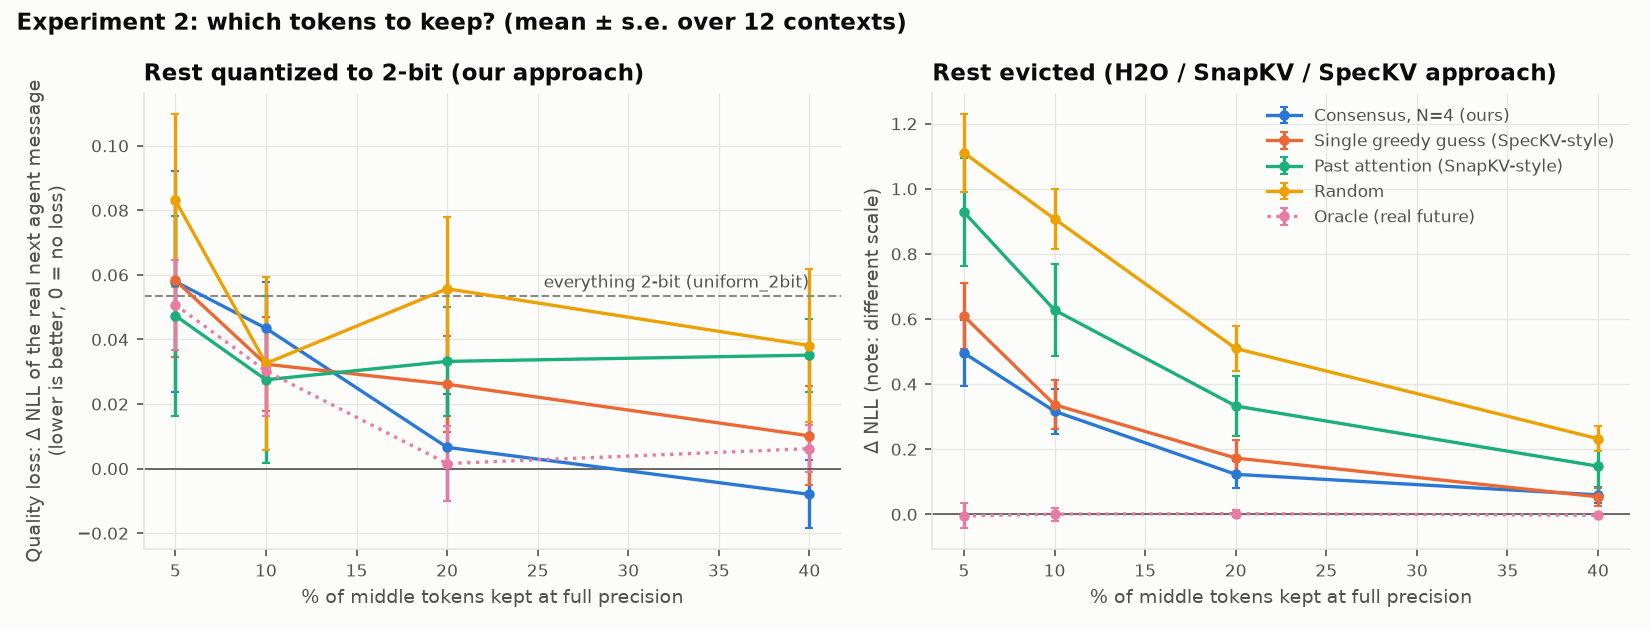

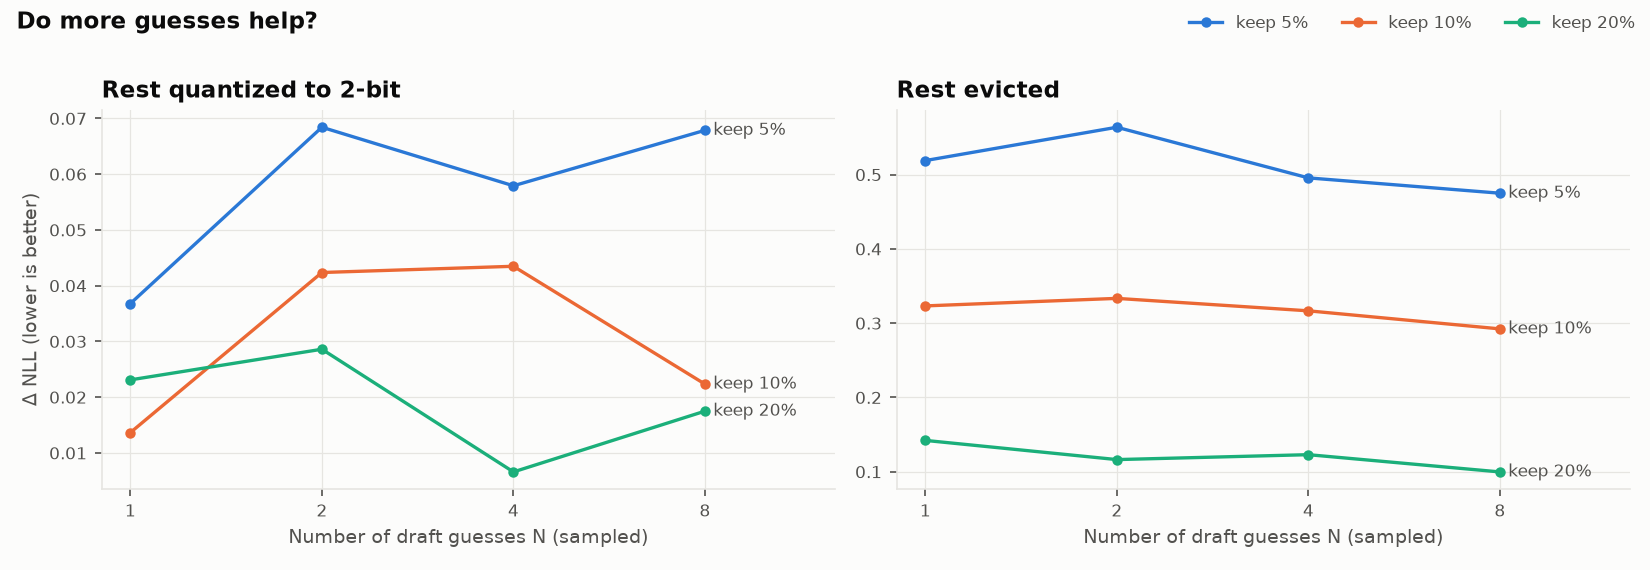

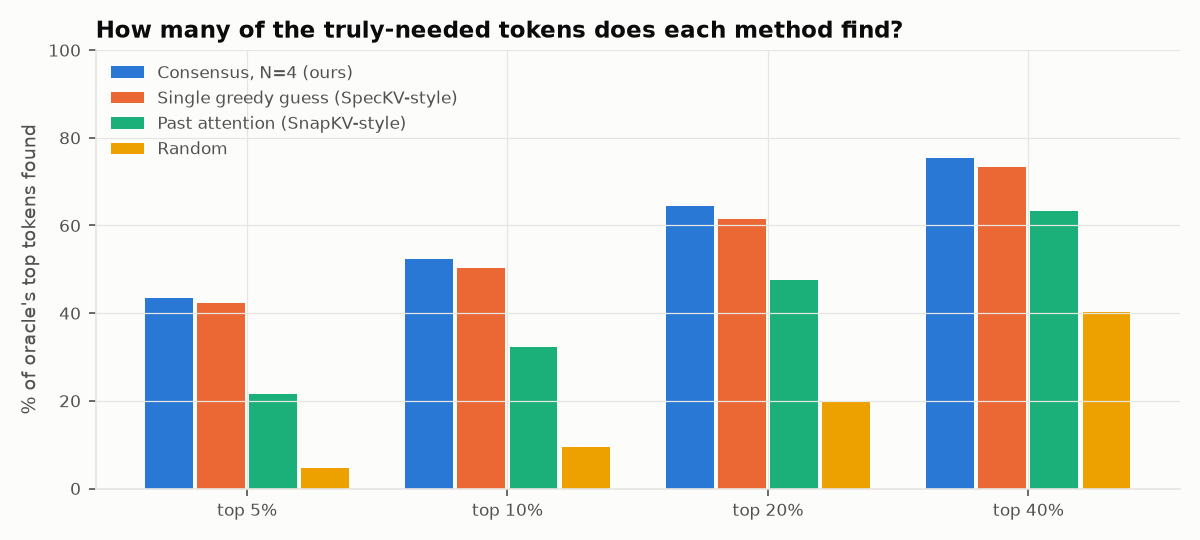

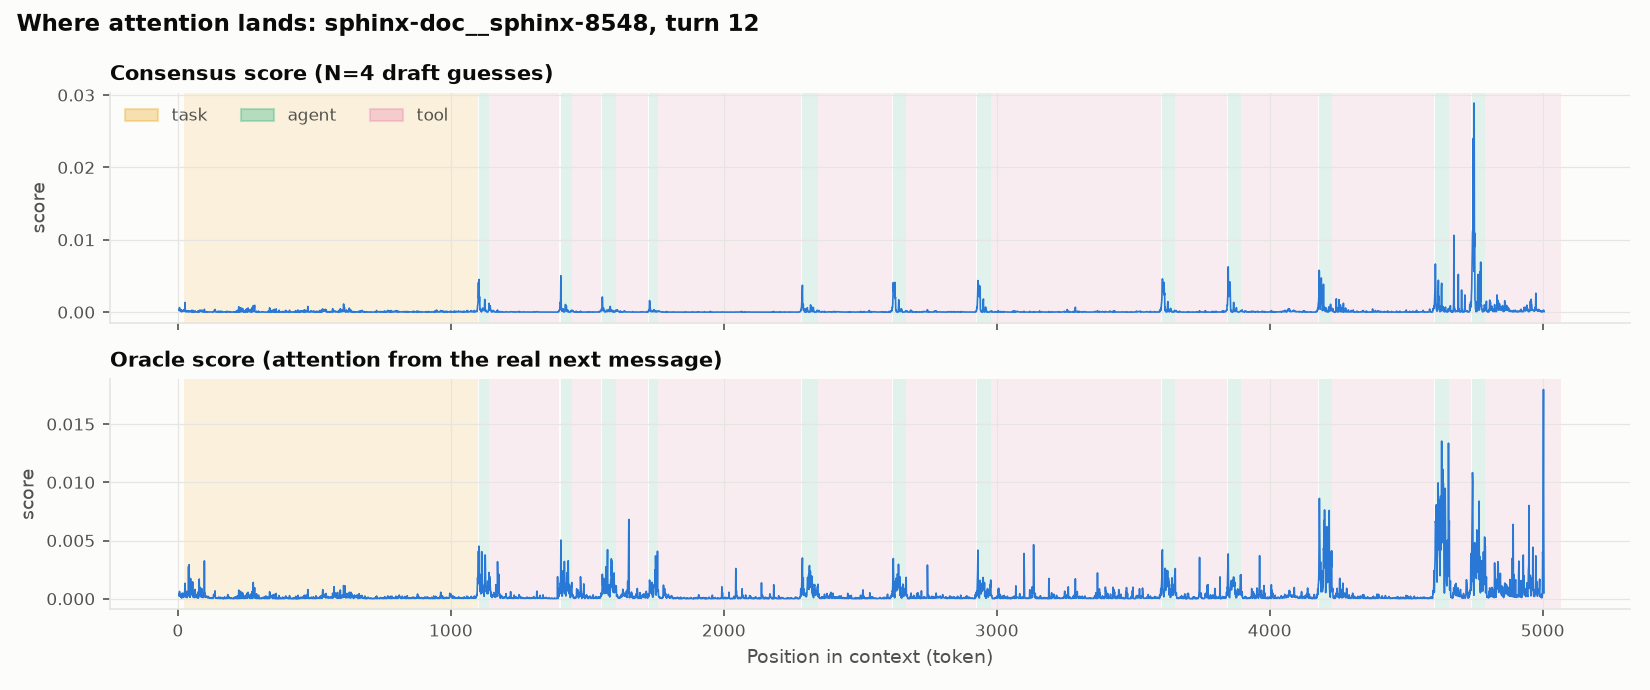

# Consensus scoring: django__django-11265 (cut at turn 7, 4037 tokens)

Scores are consensus_N4: attention from 4 sampled 10-token draft guesses, max over each guess, averaged over the 4. Sinks (first 4) and the recent window (last 64) are excluded because they are always kept.

## What the 4 draft guesses wrote next

1. `I will print lines 165 to 175 of`
2. `I will run the tests in `tests/filtered`
3. `I will run the tests for the `with_m`
4. `I will modify the existing tests in `tests/`

## What the real agent wrote next (first 300 chars)

```
I will search for occurrences of `filtered_relations` or `FilteredRelation` in `django/db/models/sql/query.py`.

```bash
grep -rn "filtered_relations" django/db/models/sql/
```<|eot_id|>
```

## Top 15 tokens (most important)

| Rank | Score | Where | Token in context |
|---|---|---|---|
| 1 | 0.0111 | agent | output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I**[ will]** print lines 135 to 155 of |
| 2 | 0.0107 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ print]** lines 135 to 155 of ' |
| 3 | 0.0097 | agent | I will print lines 135 to **[155]** of 'tests/filtered_relation/tests.py |
| 4 | 0.0080 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ print]** lines 80 to 115 from ' |
| 5 | 0.0079 | agent | output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I**[ will]** print lines 80 to 115 from |
| 6 | 0.0077 | agent |  print lines 135 to 155 of**[ ']**tests/filtered_relation/tests.py'.⏎⏎''' |
| 7 | 0.0076 | agent |  of 'tests/filtered_relation/tests.py**['.⏎⏎]**'''bash⏎sed -n '135 |
| 8 | 0.0072 | agent | </output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎**[I]** will print lines 135 to 155 |
| 9 | 0.0071 | agent | assistant<\|end_header_id\|>⏎⏎I will print lines **[135]** to 155 of 'tests/filtered |
| 10 | 0.0061 | task | , in Django tests (django/tests/**[filtered]**_relation/tests.py) if we change this |
| 11 | 0.0060 | agent | <\|end_header_id\|>⏎⏎I will run the filtered_relation**[ tests]** to see if our test suite is currently |
| 12 | 0.0060 | agent |  will print lines 135 to 155**[ of]** 'tests/filtered_relation/tests.py'.⏎⏎ |
| 13 | 0.0057 | agent |  from 'tests/filtered_relation/tests.py**['.⏎⏎]**'''bash⏎sed -n '80 |
| 14 | 0.0056 | agent |  lines 135 to 155 of '**[tests]**/filtered_relation/tests.py'.⏎⏎'''bash |
| 15 | 0.0054 | header | (⏎</output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>**[⏎⏎]**I will print lines 135 to  |

## Bottom 15 tokens (least important)

| Rank | Score | Where | Token in context |
|---|---|---|---|
| 1 | 0.000001 | task | /django/db/models/sql/query.py",**[ line]** 1028, in solve_lookup_type |
| 2 | 0.000001 | task | /django/db/models/sql/query.py",**[ line]** 1164, in build_filter⏎ |
| 3 | 0.000001 | task | 1028, in solve_lookup_type⏎**[	]**_, field, _, lookup_parts = self |
| 4 | 0.000001 | task |  line 1028, in solve_lookup**[_type]**⏎	_, field, _, lookup_parts |
| 5 | 0.000001 | task | home/lucas/dev/overmind/**[ven]**vs/release/lib/python3.6/site |
| 6 | 0.000001 | task | _to_path(lookup_splitted,**[ self]**.get_meta())⏎ File "/home/lucas |
| 7 | 0.000002 | task | /django/db/models/sql/query.py",**[ line]** 1287, in _add_q |
| 8 | 0.000002 | task | 	"Choices are: %s"**[ %]** (name, ", ".join(available |
| 9 | 0.000002 | task | /release/lib/python3.6/site-packages**[/d]**jango/db/models/sql/query.py", line |
| 10 | 0.000002 | task | /sql/query.py", line 1028**[,]** in solve_lookup_type⏎	_, field |
| 11 | 0.000002 | task | itted, self.get_meta())⏎ File "/**[home]**/lucas/dev/overmind/ven |
| 12 | 0.000002 | task | home/lucas/dev/overmind/**[ven]**vs/release/lib/python3.6/site |
| 13 | 0.000002 | task | /dev/overmind/venvs/release**[/lib]**/python3.6/site-packages/django |
| 14 | 0.000002 | task | /dev/overmind/venvs/release**[/lib]**/python3.6/site-packages/django |
| 15 | 0.000002 | task |  in solve_lookup_type⏎	_, field**[,]** _, lookup_parts = self.names_to_path |

## Where the top 10% of tokens come from

| Part of conversation | Share of context | Share of top 10% |
|---|---|---|
| system | 0% | 3% |
| task | 51% | 22% |
| agent | 8% | 40% |
| tool | 41% | 29% |
| header | 1% | 7% |


# Consensus scoring: sphinx-doc__sphinx-8548 (cut at turn 9, 4180 tokens)

Scores are consensus_N4: attention from 4 sampled 10-token draft guesses, max over each guess, averaged over the 4. Sinks (first 4) and the recent window (last 64) are excluded because they are always kept.

## What the 4 draft guesses wrote next

1. `I will view lines 810 to 820 of`
2. `I will inspect lines 812 to 820 of`
3. `I will search for lines 712 to 780`
4. `I will analyze the line that makes a copy of`

## What the real agent wrote next (first 300 chars)

```
I will search for class definitions preceding line 680 to see which class this is in.

```bash
grep -n "^class " sphinx/ext/autodoc/__init__.py | head -n 30
```<|eot_id|>
```

## Top 15 tokens (most important)

| Rank | Score | Where | Token in context |
|---|---|---|---|
| 1 | 0.0155 | agent | I will print lines 780 to **[810]** of 'sphinx/ext/autod |
| 2 | 0.0122 | agent | assistant<\|end_header_id\|>⏎⏎I will print lines **[780]** to 810 of 'sphinx/ext |
| 3 | 0.0114 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ print]** lines 780 to 810 of ' |
| 4 | 0.0087 | agent | output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I**[ will]** print lines 780 to 810 of |
| 5 | 0.0086 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ view]** lines 760 to 780 in ' |
| 6 | 0.0081 | agent | assistant<\|end_header_id\|>⏎⏎I will view lines **[760]** to 780 in 'sphinx/ext |
| 7 | 0.0079 | agent | <\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will view**[ lines]** 760 to 780 in 's |
| 8 | 0.0073 | agent |  will print lines 780 to 810**[ of]** 'sphinx/ext/autodoc |
| 9 | 0.0069 | agent | I will view lines 760 to **[780]** in 'sphinx/ext/autod |
| 10 | 0.0067 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ inspect]** lines 570 to 595 of ' |
| 11 | 0.0067 | agent | output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I**[ will]** view lines 760 to 780 in |
| 12 | 0.0067 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ print]** lines 680 to 760 in ' |
| 13 | 0.0063 | agent | <\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will inspect lines**[ ]**570 to 595 of 'sphinx |
| 14 | 0.0062 | agent | <\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will inspect**[ lines]** 570 to 595 of 's |
| 15 | 0.0060 | agent | output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I**[ will]** list the contents of the 'sphinx |

## Bottom 15 tokens (least important)

| Rank | Score | Where | Token in context |
|---|---|---|---|
| 1 | 0.000002 | tool | ⏎./tests/roots/test-ext-aut**[od]**oc/bug2437/autod |
| 2 | 0.000002 | tool | oo.py⏎./tests/roots/test**[-ext]**-doctest-with-autodoc⏎./ |
| 3 | 0.000002 | tool | ./tests/roots/test-root/aut**[od]**oc.txt⏎./tests/roots/test |
| 4 | 0.000002 | tool | ./tests/roots/test-root/aut**[od]**oc_target.py⏎./tests/roots |
| 5 | 0.000003 | tool | _dummy_module.py⏎./tests/roots**[/test]**-ext-autodoc/bug2437 |
| 6 | 0.000003 | tool | odoc.txt⏎./tests/roots**[/test]**-root/autodoc_target.py⏎ |
| 7 | 0.000003 | tool | _module.py⏎./tests/roots/test**[-ext]**-autodoc/bug2437/ |
| 8 | 0.000003 | tool | _foo.py⏎./tests/roots**[/test]**-ext-doctest-with-autodoc⏎ |
| 9 | 0.000003 | tool | ./tests/roots/test-ext-autod**[oc]**/bug2437/autodoc |
| 10 | 0.000003 | tool | oc_target.py⏎./tests/roots**[/test]**-warnings/autodoc_fod |
| 11 | 0.000003 | tool | unction.py⏎./tests/test_ext_aut**[od]**oc_configs.py⏎./tests/test_ext |
| 12 | 0.000003 | tool | _attr_docs():⏎sphinx/ext/autos**[um]**mary/generate.py:274:            |
| 13 | 0.000003 | tool | ⏎./tests/roots/test-ext-aut**[od]**oc/autodoc_dummy_module.py |
| 14 | 0.000003 | tool | ⏎./tests/roots/test-root/**[aut]**odoc.txt⏎./tests/roots |
| 15 | 0.000003 | tool | _events.py⏎./tests/test_ext_aut**[od]**oc_mock.py⏎./tests/test_ext |

## Where the top 10% of tokens come from

| Part of conversation | Share of context | Share of top 10% |
|---|---|---|
| system | 0% | 2% |
| task | 26% | 23% |
| agent | 10% | 41% |
| tool | 62% | 27% |
| header | 1% | 7% |


# Consensus scoring: sympy__sympy-12419 (cut at turn 8, 4198 tokens)

Scores are consensus_N4: attention from 4 sampled 10-token draft guesses, max over each guess, averaged over the 4. Sinks (first 4) and the recent window (last 64) are excluded because they are always kept.

## What the 4 draft guesses wrote next

1. `I will now try to find the `assert val`
2. `I will run the expressions to find the sum of`
3. `I will see if the expected result of `sum`
4. `I will check how `Identity(3)()[`

## What the real agent wrote next (first 300 chars)

```
I will check if SymPy has a KroneckerDelta.

```bash
python -c "
from sympy import KroneckerDelta, symbols
i, j = symbols('i j')
print(KroneckerDelta(i, j))
"
```<|eot_id|>
```

## Top 15 tokens (most important)

| Rank | Score | Where | Token in context |
|---|---|---|---|
| 1 | 0.0132 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ check]** how 'Identity(3)[i, |
| 2 | 0.0130 | agent | output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I**[ will]** check how 'Identity(3)[i |
| 3 | 0.0118 | agent | ]' behaves in a python terminal command**[.⏎⏎]**'''bash⏎python -c "⏎from |
| 4 | 0.0095 | agent | I will check how 'Identity(3**[)[]**i, j]' behaves in a |
| 5 | 0.0090 | agent |  'Identity(3)[i, j**[]]**' behaves in a python terminal command.⏎⏎ |
| 6 | 0.0090 | agent | (3)[i, j]'**[ behaves]** in a python terminal command.⏎⏎'''bash |
| 7 | 0.0086 | agent | Identity(3)[i, j]**[']** behaves in a python terminal command.⏎⏎''' |
| 8 | 0.0083 | agent | ⏎⏎I will check how 'Identity(**[3]**)[i, j]' behaves in |
| 9 | 0.0079 | agent | </output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎**[I]** will check how 'Identity(3)[ |
| 10 | 0.0078 | agent | <\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will check**[ how]** 'Identity(3)[i, j |
| 11 | 0.0076 | agent | assistant<\|end_header_id\|>⏎⏎I will check how '**[Identity]**(3)[i, j]' |
| 12 | 0.0070 | agent |  j]' behaves in a python terminal**[ command]**.⏎⏎'''bash⏎python -c "⏎ |
| 13 | 0.0068 | header | ⏎⏎</output><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>**[⏎⏎]**I will check how 'Identity(3 |
| 14 | 0.0068 | agent | ><\|eot_id\|><\|start_header_id\|>assistant<\|end_header_id\|>⏎⏎I will**[ grep]** for class 'Identity' in 'sy |
| 15 | 0.0063 | agent | <\|end_header_id\|>⏎⏎I will check how 'Identity**[(]**3)[i, j]' behaves |

## Bottom 15 tokens (least important)

| Rank | Score | Where | Token in context |
|---|---|---|---|
| 1 | 0.000002 | tool | s from 'collections' instead of from**[ ']**collections.abc' is deprecated since Python |
| 2 | 0.000002 | tool | s from 'collections' instead of from**[ ']**collections.abc' is deprecated since Python |
| 3 | 0.000002 | tool | : Using or importing the ABCs from**[ ']**collections' instead of from 'collections. |
| 4 | 0.000003 | task | - installation, build, packaging, configuration**[,]** or setup scripts unless they are directly part |
| 5 | 0.000003 | tool |  Python 3.3, and in**[ ]**3.10 it will stop working⏎ |
| 6 | 0.000003 | tool | entry(self, i, j):⏎sy**[mp]**y/matrices/expressions/matmul |
| 7 | 0.000003 | tool |  is deprecated since Python 3.3**[,]** and in 3.10 it will |
| 8 | 0.000003 | tool | collections.abc' is deprecated since Python**[ ]**3.3, and in 3 |
| 9 | 0.000003 | task |  created⏎- installation, build, packaging**[,]** configuration, or setup scripts unless they are |
| 10 | 0.000003 | tool |  from 'collections.abc' is deprecated**[ since]** Python 3.3, and in |
| 11 | 0.000003 | tool |  deprecated since Python 3.3,**[ and]** in 3.10 it will stop |
| 12 | 0.000003 | tool |  since Python 3.3, and**[ in]** 3.10 it will stop working |
| 13 | 0.000003 | tool |  deprecated since Python 3.3,**[ and]** in 3.10 it will stop |
| 14 | 0.000003 | task |  that you created⏎- installation, build**[,]** packaging, configuration, or setup scripts unless |
| 15 | 0.000004 | tool | entry(self, i, j):⏎sy**[mp]**y/matrices/expressions/transpose |

## Where the top 10% of tokens come from

| Part of conversation | Share of context | Share of top 10% |
|---|---|---|
| system | 0% | 1% |
| task | 32% | 26% |
| agent | 19% | 42% |
| tool | 48% | 26% |
| header | 1% | 5% |


In [20]:
!python exp2_plot.py
import glob
for name in ['exp2_summary.md', 'exp2_quality_vs_keep.png', 'exp2_n_sweep.png', 'exp2_recall.png',
             'exp2_score_profile.png']:
    show(f'results/exp2/{name}')
for path in sorted(glob.glob('results/exp2/top_tokens_*.md')):
    show(path)

## 9. Save a zip of all results to Google Drive

In [21]:
import shutil
zip_path = shutil.make_archive(f'{DRIVE_DIR}/kv_cache_results', 'zip', root_dir='results')
print('Saved', zip_path)
print('Individual result files are in', f'{DRIVE_DIR}/results')

Saved /content/drive/MyDrive/kv_cache_experiments/kv_cache_results.zip
Individual result files are in /content/drive/MyDrive/kv_cache_experiments/results
